**Текущий объём на 10 ноября: 315 уникальных задач с сохранёнными разборами; 312 задач в основных частотах.** Состав: исходные 100 + первые дополнительные 100 Богдана + 50 Sol + следующие 65 Богдана. Все числа относятся к разборам задач, а не ко всему банку из 1148 условий.

**Где смотреть обновление:** [глава 12](#12-обновление-10-ноября-опубликованные-данные-богдана) — сводка 100 → 200 → 250 → 315 и новые аудиты. Разделы 1–10 и их графики сохраняют исторический анализ 100 задач; прежняя строка «Объём» ниже относится к нему. Таблицы частот, сочетаний и переходов для 315 задач: [датированный отчёт](../../data/annotation/analyses/2026-11-10-saved-data-refresh-v1/report.md) и [таблицы](../../data/annotation/analyses/2026-11-10-saved-data-refresh-v1/tables/).

**Навигация по версиям:** разделы 1–10 — исторические 100 разборов (98 в частотах); [глава 11](#11-дополнение-9-ноября-250-разборов-доменные-проверки-и-ml-baseline) — дополнение 9 ноября, 250 разборов (247 по единой политике).

# EDA. От материалов ФИПИ к предметной модели тьютора

**Проект №65, профильный ЕГЭ по математике. Предварительная версия для обсуждения с командой и куратором, 5 ноября 2026.**

### Какие вопросы к данным возникают при создании тьютора

В основе проекта - инструмент для регулярной подготовки к профильному ЕГЭ между занятиями с преподавателем. Он должен помогать разбирать решение и находить упражнения для дальнейшей практики. Для этого нужна предметная база: задачи, математические действия, объяснения и связи между ними.

В [обзоре подходов к тьюторам](../../research/deep-research-llm-based-its.md) мы разделяли поиск учебного контекста (RAG) и выбор педагогического действия. RAG помогает найти материал по запросу. Для тьютора важно ещё понимать, какое действие требуется в задаче, что уже известно перед ним и какой материал подходит для его отработки. В EDA исследуем данные для такой организации содержания:

- **На какие материалы можно опереться?** Что доступно в ФИПИ, какие метаданные есть и как сохранить формулы и рисунки без потерь?
- **По каким признакам искать упражнения?** Что добавляют шаги решения и KC к официальной теме и типу задания?
- **Какие задачи связаны общим действием?** Где повторяется одно умение, а где за одинаковой меткой скрываются разные условия или маршруты решения?
- **Что нужно хранить для объяснения и проверки шага?** Достаточно ли названия KC или нужны исходное состояние, ожидаемый результат, ограничения и свидетельства из решения?

Ответы определяют, как организовать материалы для поиска, объяснений и практики в будущем прототипе. Индивидуальный профиль и выбор помощи по истории ученика относятся к следующему слою системы; здесь анализируем предметное содержание.

**Объём:** 1148 условий банка; 100 задач с предварительными разборами; 98 задач в основных частотах. Последующий качественный разбор использует 19 из этих задач, в том числе все 12 принятых применений линейного уравнения. Это вложенные, а не складываемые объёмы.

### Содержание

1. [Из чего исходили и как менялся вопрос](#1-из-чего-исходили-и-как-менялся-вопрос) - Исходная идея, вопросы к данным и понятия; пример агентного разбора.
2. [ФИПИ как источник: что получили и где границы](#2-фипи-как-источник-что-получили-и-где-границы) - Состав банка, форматы условий и повторяющиеся заготовки.
3. [Как отобраны 100 задач](#3-как-отобраны-100-задач) - Отбор 100 задач и распределение по темам ФИПИ.
4. [Как устроены разборы: сколько шагов и KC содержит задача](#4-как-устроены-разборы-сколько-шагов-и-kc-содержит-задача) - Длина решений, шаги и число описаний KC.
5. [Какие действия повторяются между задачами](#5-какие-действия-повторяются-между-задачами) - Частоты, сочетания действий и связь тем с KC.
6. [Как каталог описывает действия из дополнительных задач](#6-как-каталог-описывает-действия-из-дополнительных-задач) - Роль аудитора, статусы сопоставления и примеры.
7. [Как проверяли дополнительные разборы и что обнаружили](#7-как-проверяли-дополнительные-разборы-и-что-обнаружили) - Проверки партий, исправления и обнаруженные проблемы.
8. [Как результаты разметки связаны с будущим тьютором](#8-как-результаты-разметки-связаны-с-будущим-тьютором) - Три сопоставления и подробный разбор 12 применений линейного уравнения.
9. [Итог: что мы узнали и что берём в проект](#9-итог-что-мы-узнали-и-что-берём-в-проект) - Выводы, пример предполагаемой помощи ученику и ограничения.
10. [Источники, данные и результаты проверок](#10-источники-данные-и-результаты-проверок) - Источники, таблицы, происхождение и журнал проверок.
11. [Дополнение 9 ноября: 250 разборов, доменные проверки и ML baseline](#11-дополнение-9-ноября-250-разборов-доменные-проверки-и-ml-baseline)
12. [Обновление 10 ноября: опубликованные данные Богдана](#12-обновление-10-ноября-опубликованные-данные-богдана)

## 1. Из чего исходили и как менялся вопрос

Хотим создать тьютора по всей программе профильного ЕГЭ по математике: ученик выполняет действие, система проверяет ответ, при необходимости помогает и предлагает дальнейшую практику. Для этого мало хранить только тему и итоговый ответ задачи: нужно понимать содержание решения и сохранять основания проверки.

**Начальная гипотеза:** решения можно представить содержательными шагами и кандидатами математических умений — KC. Повторения таких действий между задачами могут дать основу для организации упражнений. Совместная встречаемость может предложить места для просмотра, но сама не устанавливает метод, зависимость навыков или порядок обучения.

Мы искали ответ на три вопроса:

- Что реально содержится в источнике и можно ли сохранить математические условия без потерь?
- Какие повторяющиеся действия видны в разборах и насколько каталог описывает новые задачи?
- Что из этой разметки уже позволяет проектировать учебное действие, а чего для тьютора пока не хватает?

### Путь исследования: решения и основания

| Этап | Что делали и каким методом | Что взяли дальше | Ограничение |
|---|---|---|---|
| Рамка экзамена и проекта | Изучали официальные материалы и структуру профильного ЕГЭ; формулировали вопросы предметной модели | Охват всей программы; различение предметной модели и индивидуального профиля | Карта требований не означает реализованную систему или проверенное покрытие банка |
| Ранние пробы на другом источнике | Во время недоступности ФИПИ собрали один вариант «Решу ЕГЭ» из 19 задач; пробовали инструкции A/B/C, повторы и привязки к требованиям | Формат шагов, локальных KC, контекста и свидетельств; A как предварительная основа последующих инструкций | Это разработка методики; строгий победитель промптов и общий эталон не установлены. Эти 19 не прибавляются к текущим 100 ФИПИ |
| Проверка границ KC | Сопоставляли определения с примерами и контрпримерами, разбирали роль входного состояния; изучали сохранённый опыт прежнего проекта и исследовательские материалы | Сохранять действия и происхождение; не требовать максимального дробления; различать общий компонент и полный метод | Предложения и малые известные случаи не доказывают освоение навыка или устойчивость на всём экзамене |
| Снимок ФИПИ | Скачали страницы и изображения, разобрали представление, проверяли целостность и отображение партиями | Условия и метаданные 1148 задач для описательного анализа | Ответы и решения этим сбором не получены |
| Пилот 50 | Отбор для разнообразия; самостоятельные разборы основного ассистента в общем контексте; отдельное редакторское сопоставление | Предварительный каталог из 144 определений, первые частоты и спорные границы | Нет внешнего экспертного эталона и изолированных независимых повторов |
| Расширение 50→100 | Замороженная псевдослучайная очередь, новые авторы и аудиторы в отдельных контекстах, проверки между партиями | Проверка применения фиксированного каталога к новым задачам | Процедура отличается от пилота; сравнение не является причинным экспериментом |
| Содержательное продолжение EDA | Структурный пересчёт и целевые сопоставления сохранённых условий/шагов; явные редакторские описания входа и результата | Требования к единице учебного содержания: вход, действие, результат, условия и область проверки | Исследовательский отбор после просмотра; новых данных учеников и проверки эффективности нет |

Ни одно из этих исследований не заменяет предметную экспертизу. Выводы ниже относятся к сохранённым данным и указанным процедурам.

### Как устроены данные: от карточки ФИПИ к разбору решения

**ФИПИ** - Федеральный институт педагогических измерений. Его открытый банк содержит задания для подготовки к ЕГЭ; в проекте используем банк математики профильного уровня. На сайте задания представлены карточками: условие, формулы и рисунки, номер задания, метки содержания и тип ответа. Для исследования сохранён снимок этого банка на 31 октября 2026 года.

**Что содержит запись задания в нашем наборе:**

| Часть записи | Что хранится и зачем |
|---|---|
| Идентификаторы и источник | Короткий ID задания, полный GUID, проект банка, страница и ссылка на карточку - для связи записи с оригиналом |
| Условие | Текст и исходный HTML; формулы MathML и ссылки на сохранённые рисунки - для точного представления математического содержания |
| Метаданные ФИПИ | КЭС и тип ответа: краткий или развёрнутый - для описания состава банка и отбора задач |
| Происхождение и проверки | Дата снимка, исходная страница, контрольные хеши и отметки дефектов источника - для проверки сохранности материалов |

**КЭС (код элемента содержания)** - метка банка, указывающая, к какому математическому содержанию относится задание. Например, у задачи `40B442` сохранена метка «7.5 Координаты и векторы». Одна задача может иметь несколько таких меток. Это классификация исходного банка; она сохраняется отдельно от разметки решений.

**Что добавляем при разборе задач:**

| Понятие | Смысл в проекте | Пример |
|---|---|---|
| Шаг решения (Step) | Содержательное действие с указанным результатом и необходимым контекстом | Составить уравнение по условию задачи |
| Компонент знания (KC, Knowledge Component) | Описание математического действия или умения, которое ищем в разных решениях | Решение линейного уравнения |
| Метод (Method) | Маршрут решения или его содержательная часть, связывающая несколько шагов | Составить уравнение → решить его → интерпретировать результат |
| Каталог KC | Общий набор определений для сопоставления действий между задачами | Отнести действия из разных решений к одному определению |
| Назначение KC | Сохранённая связь действия в конкретном разборе с определением каталога | Связать шаг решения уравнения с соответствующим KC |

КЭС помогает найти задачи по математическому содержанию, а шаги, KC и методы описывают, **что именно выполняется в решении**. Например, задачи разных тем могут содержать общее действие - решение линейного уравнения.

**Как подготовлена разметка.** Разобраны 100 задач в два этапа по 50: сначала пилот для отработки представления шагов и KC, затем расширение с агентным аудитом и промежуточными проверками партий. Для сопоставления использован каталог из 144 определений. [Методика разметки](../../docs/eda/04-annotation/README.md) и [протокол расширения](../../docs/eda/04-annotation/12-expansion-50-to-200.md) описывают процедуру подробнее.

### Пример: карточка ФИПИ и результат разбора

Задача `282EDC` показывает, как исходное условие превращается в шаги, описания умений и метод решения. Ниже приведены сохранённый рисунок и ответ агента; обозначения `s1`, `k1`, `m1` связывают части одного разбора.

**Условие ФИПИ · 282EDC**  
КЭС: 7.1 Фигуры на плоскости; Тип ответа: Краткий ответ

Площадь параллелограмма ABCD равна 24. Точка E — середина стороны AD. Найдите площадь трапеции BCDE.

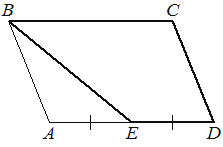

**Разбор агента**

**s1. Выразить площадь треугольника ABE через площадь параллелограмма, используя основание AE и общую высоту к прямой AD.**

Поскольку E — середина AD, AE=AD/2. Высота из B к AD равна высоте параллелограмма h, поэтому S_ABE=(1/2)·AE·h=(1/4)·AD·h=24/4=6.

Связанные KC: `k1`.

**s2. Вычесть площадь отсечённого треугольника из площади параллелограмма.**

Отрезок BE делит параллелограмм на треугольник ABE и трапецию BCDE без перекрытия внутренних областей. S_BCDE=24−6=18.

Связанные KC: `k2`.

**Компоненты знания в этом разборе**

**k1 · Сопоставлять площади треугольника и параллелограмма по общей высоте**

Для треугольника с основанием на стороне параллелограмма и противоположной вершиной на параллельной стороне выразить отношение площадей как половину отношения оснований, используя общую высоту и формулы площадей.

**k2 · Находить площадь остатка фигуры вычитанием**

Если фигура разбита на две части с непересекающимися внутренними областями, найти площадь одной части как разность площади всей фигуры и известной площади другой части.

**Метод m1:** Площадь трапеции как дополнение треугольника с половинным основанием  
Маршрут: s1 → s2.

**Ответ агента:** 18.

**Сопоставление с каталогом:** аудитор отметил оба KC как `new_candidate`. Это предложения новых определений: они сохранены отдельно от общего каталога. Для первого действия аудитор различил использование общей высоты и подобие фигур; во втором выделил нахождение площади остатка вычитанием.

[Исходная запись](../../data/annotation/runs/2026-11-02-fipi-extension-150/inputs/tasks/282EDC.json) · [Полный ответ агента](../../data/annotation/runs/2026-11-02-fipi-extension-150/raw/author/282EDC.json) · [Аудит](../../data/annotation/runs/2026-11-02-fipi-extension-150/raw/auditor/282EDC.json)

In [1]:
from pathlib import Path
import json, re
from lxml import html as example_dom
from IPython.display import display, Markdown, Image
example_root=next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'scripts/build_checkpoint2.py').exists())
example_run=example_root/'data/annotation/runs/2026-11-02-fipi-extension-150'
example_id='282EDC'
example_input=json.loads((example_run/'inputs/tasks'/f'{example_id}.json').read_text(encoding='utf-8'))
example_author=json.loads((example_run/'raw/author'/f'{example_id}.json').read_text(encoding='utf-8'))
example_audit=json.loads((example_run/'raw/auditor'/f'{example_id}.json').read_text(encoding='utf-8'))
example_text=re.sub(r'\s+', ' ', example_dom.fromstring(example_input['statement_html']).text_content()).strip()
example_meta='; '.join(m['label']+' '+', '.join(m['values']) for m in example_input['metadata'])
display(Markdown('**Условие ФИПИ · '+example_id+'**  \n'+example_meta+'\n\n'+example_text))
for asset in example_input['assets']:
    display(Image(filename=str(example_run/'inputs'/asset['path']),width=280))
display(Markdown('**Разбор агента**'))
for step in example_author['steps']:
    display(Markdown('**'+step['id']+'. '+step['action']+'**\n\n'+step['result']+'\n\nСвязанные KC: `'+ '`, `'.join(step['kc_ids'])+'`.'))
display(Markdown('**Компоненты знания в этом разборе**'))
for kc in example_author['kc_candidates']:
    display(Markdown('**'+kc['id']+' · '+kc['name']+'**\n\n'+kc['description']))
for method in example_author['methods']:
    display(Markdown('**Метод '+method['id']+':** '+method['name']+'  \nМаршрут: '+' → '.join(method['step_ids'])+'.'))
display(Markdown('**Ответ агента:** '+example_author['answer']+'.'))
assert {d['status'] for d in example_audit['decisions']}=={'new_candidate'}
display(Markdown('**Сопоставление с каталогом:** аудитор отметил оба KC как `new_candidate`. Это предложения новых определений: они сохранены отдельно от общего каталога. Для первого действия аудитор различил использование общей высоты и подобие фигур; во втором выделил нахождение площади остатка вычитанием.'))
display(Markdown('[Исходная запись](../../data/annotation/runs/2026-11-02-fipi-extension-150/inputs/tasks/282EDC.json) · [Полный ответ агента](../../data/annotation/runs/2026-11-02-fipi-extension-150/raw/author/282EDC.json) · [Аудит](../../data/annotation/runs/2026-11-02-fipi-extension-150/raw/auditor/282EDC.json)'))

In [2]:
from pathlib import Path
import sys, json
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
root=next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'scripts/build_checkpoint2.py').exists())
sys.path.insert(0,str(root/'scripts'))
from build_checkpoint2 import analyze, integrated_inputs, OUT, BASE, EXT
data, summary, tables, bank_stats, bank, composition=analyze()
integrated, bridge=integrated_inputs()
task_by_id={r['task_id']:r for r in data['baseline']+data['new']}
names={r['id']:r['name'] for r in data['catalog']['nodes']}
def table(rows):
    rows=list(rows)
    if not rows:return
    def plain(v):return str(v).replace('|', '/').replace('\n',' ')
    keys=list(rows[0])
    lines=['| '+' | '.join(map(plain,keys))+' |','|'+'|'.join('---' for _ in keys)+'|']
    lines+=['| '+' | '.join(plain(r[k]) for k in keys)+' |' for r in rows]
    display(Markdown('\n'.join(lines)))
def chart(name):
    plt.tight_layout();plt.savefig(OUT/(name+'.png'),dpi=150,bbox_inches='tight');plt.close()
    display(Image(filename=str(OUT/(name+'.png'))))
print('Пересчитаны банк и 100 разборов; основные показатели по 98. Проверены 166 полей свидетельств содержательного продолжения.')

Frozen bytes verified, including archived paths.


Пересчитаны банк и 100 разборов; основные показатели по 98. Проверены 166 полей свидетельств содержательного продолжения.


## 2. ФИПИ как источник: что получили и где границы

ФИПИ — Федеральный институт педагогических измерений. В проекте используем снимок его **открытого банка заданий ЕГЭ по математике профильного уровня**, проект AC437B34557F88EA4115D2F374B0A07B. Банк даёт реальные условия и метки содержания; это не набор взаимодействий учеников и не готовая карта навыков.

Источник снимка: [открытый банк профильной математики ФИПИ](https://ege.fipi.ru/bank/index.php?proj=AC437B34557F88EA4115D2F374B0A07B). Все числа в этом ноутбуке относятся к **снимку 31 октября 2026**, а не к текущему состоянию сайта. Год конкретной задачи не установлен; распределение банка не равно структуре экзамена определённого года.

### Как собирали и проверяли

Сохранены исходные ответы сервера Windows-1251, 115 страниц, структурированные записи JSONL/JSON, оригинальные PNG/GIF, URL и SHA-256. Проверяли ID/GUID, число задач, полноту текста, деревья MathML и декодирование изображений. После каждой из 23 партий проверяли накопленный набор; целевой браузерный контроль охватил 130 карточек. Это техническая и выборочная визуальная проверка, не математическая экспертиза 1148 условий.

### Что есть в записи задачи

| Группа полей | Содержание и роль |
|---|---|
| ID, GUID, URL, страница, дата снимка | Прослеживаемость источника и устранение повторов ID |
| Условие, исходный фрагмент, MathML, изображения | Содержание задачи; формула может находиться и в картинке |
| КЭС и формат ответа | Буквальные метаданные банка; одна задача может иметь несколько КЭС |
| Предупреждения, размеры, SHA-256 | Контроль источника и целостности |
| Ответ, решение, год экзамена | Не получены / не установлены в этом сборе; не подставляем предположения |

Первый КЭС — воспроизводимая группировка по первой метке источника, а не назначенный нами главный навык. Метки банка не приравниваются к KC или к кодификатору другой редакции. Отсутствие кода среди первых меток не доказывает пробел официальной программы.

| Показатель | Значение |
|---|---|
| Условий | 1148 |
| Разных первых КЭС | 26 |
| Разных КЭС среди всех меток | 29 |
| Назначений меток КЭС | 1707 |
| Задач с изображениями | 286 |
| Задач с MathML | 859 |
| Задач с предупреждением источника | 1 |

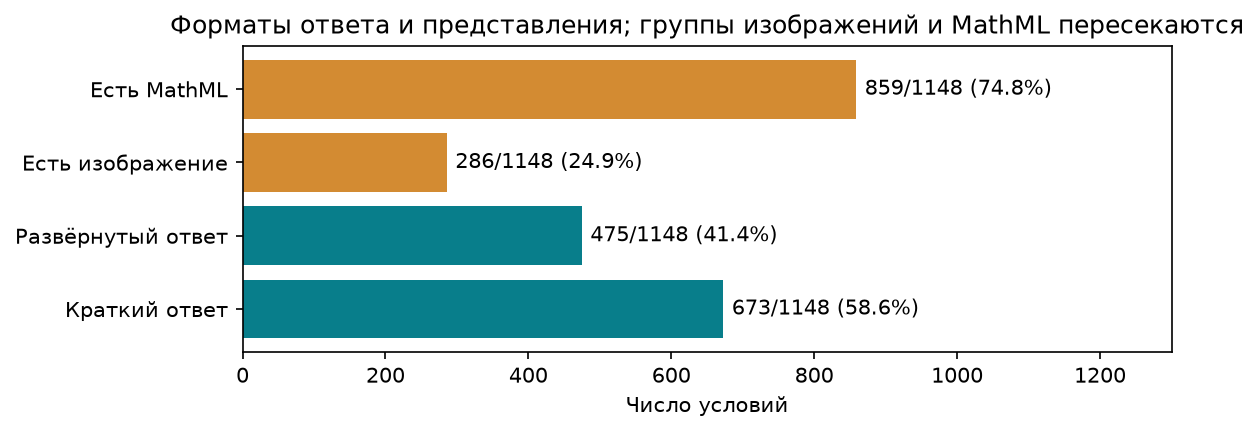

In [3]:
table([{'Показатель':label,'Значение':bank_stats[k]} for k,label in [('tasks','Условий'),('first_codes','Разных первых КЭС'),('all_codes','Разных КЭС среди всех меток'),('label_assignments','Назначений меток КЭС'),('images','Задач с изображениями'),('mathml','Задач с MathML'),('source_issues','Задач с предупреждением источника')]])
fig, ax=plt.subplots(figsize=(8,3))
labels=['Краткий ответ','Развёрнутый ответ','Есть изображение','Есть MathML']
values=[bank_stats['short'],bank_stats['tasks']-bank_stats['short'],bank_stats['images'],bank_stats['mathml']]
bars=ax.barh(labels,values,color=['#087e8b','#087e8b','#d38b32','#d38b32'])
ax.bar_label(bars,labels=[f'{n}/1148 ({n/1148:.1%})' for n in values],padding=4)
ax.set_xlim(0,1300);ax.set_xlabel('Число условий');ax.set_title('Форматы ответа и представления; группы изображений и MathML пересекаются')
chart('01-bank-formats')

**Что показывают форматы ответа.** У 673 из 1148 заданий указан **краткий ответ**: требуется записать итог, например число или последовательность значений. У 475 указан **развёрнутый ответ**: требуется представить решение с обоснованием, доказательством или ответами на несколько пунктов. Эти две категории делят банк по формату ожидаемого ответа; вместе они составляют 100% заданий. Для тьютора это различие важно: проверка итога и работа с ходом решения требуют разных представлений ответа ученика.

**Как представлены условия.** В 286 заданиях есть изображения, в 859 - формулы MathML (формат структурированной записи формул на веб-странице). Это отдельные признаки, которые могут присутствовать одновременно: **196 задач содержат и изображение, и MathML**. Например, в условии может быть геометрический рисунок и формула рядом с ним. Поэтому две последние полосы графика нельзя складывать как доли разных частей банка. Изображение также может содержать формулу, а не рисунок фигуры. Для сохранения условия нужны текст, формулы и файлы изображений вместе.

### Проверка качества: повреждённые условия и повторяющиеся заготовки

У задачи `697AC9` найден дефект символа в самом источнике; она исключена до отбора. Отдельно проверили, нет ли в банке повторов одного задания под разными ID:

- **Полное совпадение по принятому правилу:** сравниваем структуру и текст условия после нормализации пробелов, инструкцию и содержимое изображений по хешам.
- **Совпадение после замены чисел:** заменяем числовые значения в тексте и формулах общим маркером и повторяем сравнение. Так ищем задания с одинаковой заготовкой и разными числами; изображения при этом должны совпадать по хешу.

Это проверка устройства банка, а не отдельная разметка навыков. Её смысл - понять, сколько заданий могут оказаться вариациями одной заготовки, и учитывать это при оценке разнообразия практики.

In [4]:
table([{'Критерий':'Группы строгих совпадений','Групп':bank_stats['exact_groups']},
       {'Критерий':'Группы совпадений после замены чисел маркером','Групп':bank_stats['template_groups']}])
from analyze_fipi50 import key_condition
from lxml import html as condition_dom
variants={r['id']:r for r in bank if r['id'] in ('997E04','6E7D00')}
assert key_condition(variants['997E04'],True)==key_condition(variants['6E7D00'],True)
assert key_condition(variants['997E04'])!=key_condition(variants['6E7D00'])
display(Markdown('**Пример найденной заготовки: одинаковый вопрос, разные количества фломастеров.**'))
table([{'ID':tid,'Условие':' '.join(condition_dom.fromstring(variants[tid]['statement_html']).text_content().split())} for tid in ('997E04','6E7D00')])

| Критерий | Групп |
|---|---|
| Группы строгих совпадений | 0 |
| Группы совпадений после замены чисел маркером | 90 |

**Пример найденной заготовки: одинаковый вопрос, разные количества фломастеров.**

| ID | Условие |
|---|---|
| 997E04 | В коробке 5 синих, 9 красных и 11 зелёных фломастеров. Случайным образом выбирают два фломастера. Найдите вероятность того, что окажутся выбраны один синий и один красный фломастеры. |
| 6E7D00 | В коробке 6 синих, 9 красных и 10 зелёных фломастеров. Случайным образом выбирают два фломастера. Найдите вероятность того, что окажутся выбраны один синий и один красный фломастеры. |

**Вывод.** По правилу полного совпадения повторов не найдено. После замены чисел обнаружено **90 групп**, в каждой не менее двух заданий с совпавшей заготовкой. Это число групп, а не число задач и не количество методов решения.

В примере выше меняется состав коробки, а формулировка вопроса сохраняется. Такие варианты могут быть полезны для повторной тренировки. Но два разных ID ещё не означают два разных способа решения: размер банка нельзя напрямую считать мерой разнообразия упражнений. Для будущей оценки тьютора также важно различать решение числовой вариации знакомой задачи и применение умения в новом контексте. Совпадение заготовки - технический признак для такого анализа; одинаковый метод оно само по себе не доказывает.

## 3. Как отобраны 100 задач

Первые 50: по одному из 38 непустых сочетаний «первый КЭС × формат ответа», ещё 12 мест распределены по размеру страт. Выбор предназначен для разнообразия и перепредставляет редкие категории.

Расширение: из оставшихся 1097 допустимых задач заранее заморожена очередь 150, ранжированная SHA-256 от `seed + "|" + ID`; seed — `fipi-extension-150-v1-2026-11-02`. Выполнены только первые 50: партии 15+15+15+5 с проверками. Это псевдослучайное дополнение к специально отобранному пилоту; совокупные 100 не являются простой случайной выборкой банка. [Manifest пилота](../../data/annotation/runs/2026-10-31-fipi-50x1/manifest.json) · [Очередь расширения](../../data/annotation/runs/2026-11-02-fipi-extension-150/selection.json).

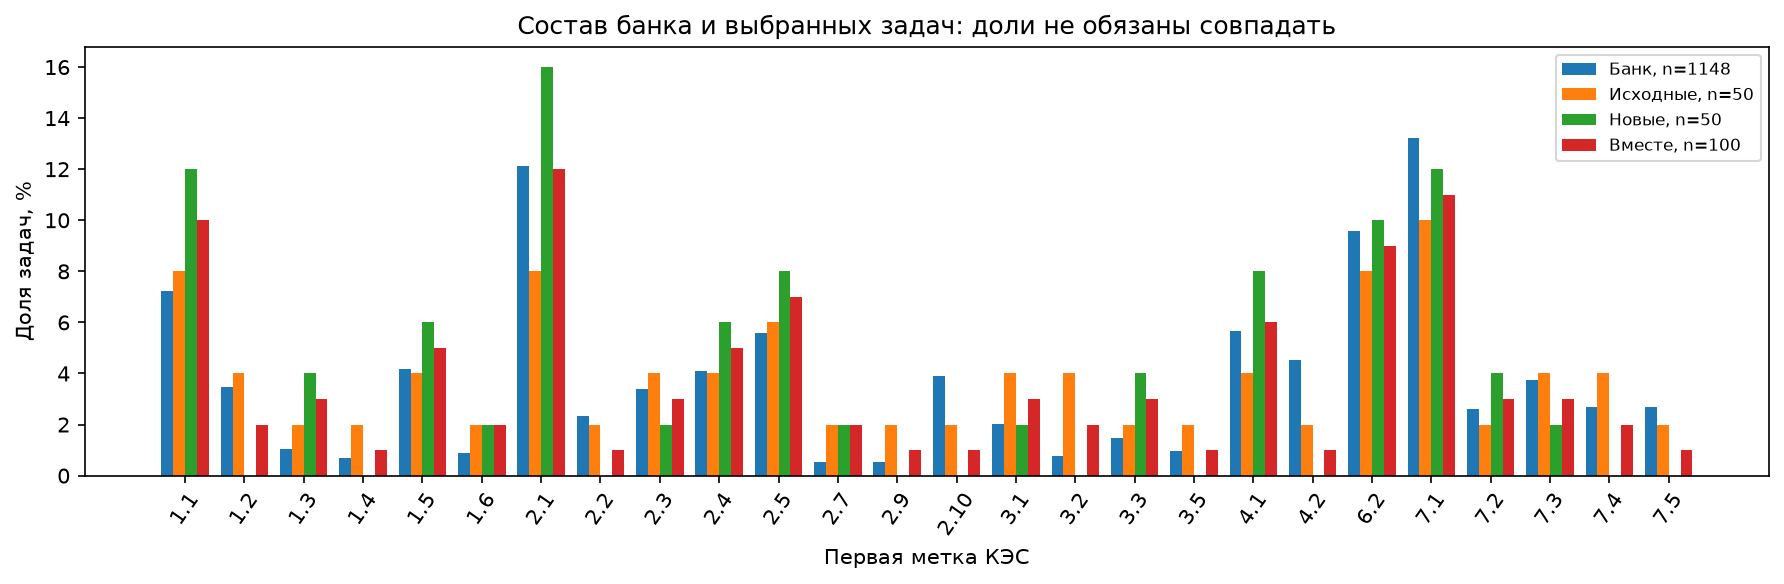

In [5]:
layers=list(dict.fromkeys(r['layer'] for r in composition))
codes=sorted({r['code'] for r in composition},key=lambda k:tuple(map(int,k.split('.'))))
fig, ax=plt.subplots(figsize=(12,4));x=np.arange(len(codes));width=.2
for j,layer in enumerate(layers):
    counts={r['code']:r['percent'] for r in composition if r['layer']==layer}
    ax.bar(x+(j-1.5)*width,[counts[c] for c in codes],width,label=layer)
ax.set_xticks(x,codes,rotation=55);ax.set_ylabel('Доля задач, %');ax.set_xlabel('Первая метка КЭС');ax.legend(fontsize=8);ax.set_title('Состав банка и выбранных задач: доли не обязаны совпадать')
chart('02-selection')

**Как читать график состава.** По горизонтали указаны первые метки КЭС - группы математического содержания банка. Для каждого кода рядом стоят четыре столбца: весь банк, первые 50 задач, дополнительные 50 и все 100 вместе. Высота - доля задач с этой первой меткой внутри соответствующей группы. Например, столбец на уровне 10% для выборки из 50 означает пять задач. Если столбцы банка и выборки различаются, соответствующая группа представлена в выборке в другой пропорции.

**Что получилось.** Первые 50 отбирались для охвата разных сочетаний содержания и формата ответа; следующие 50 добавили задачи из заранее зафиксированной псевдослучайной очереди. В итоге получились 60 задач с кратким и 40 с развёрнутым ответом: 29/21 в первой части и 31/19 во второй. Доля кратких ответов - 60% против примерно 58,6% в банке. По этому признаку состав близок, но распределение по КЭС нужно оценивать отдельно по столбцам графика.

**Зачем это учитывать дальше.** Этот набор позволяет искать повторяющиеся действия в разных задачах. Но он специально составлялся для разнообразия, а не для точного воспроизведения долей банка. Поэтому найденную частоту KC читаем как «встречается в стольких-то разобранных задачах», а не как вероятность встретить это умение на экзамене. Пересчёт частот на весь банк потребовал бы отдельной схемы отбора и учёта долей его групп.

### Какие разделы представлены в 100 задачах

Здесь учитываем **все КЭС задачи**, сгруппированные по первой части кода банка. Внутри раздела задача учитывается один раз, даже если у неё несколько меток этого раздела. Столбец показывает число задач из наших 100; одна задача может относиться к нескольким разделам.

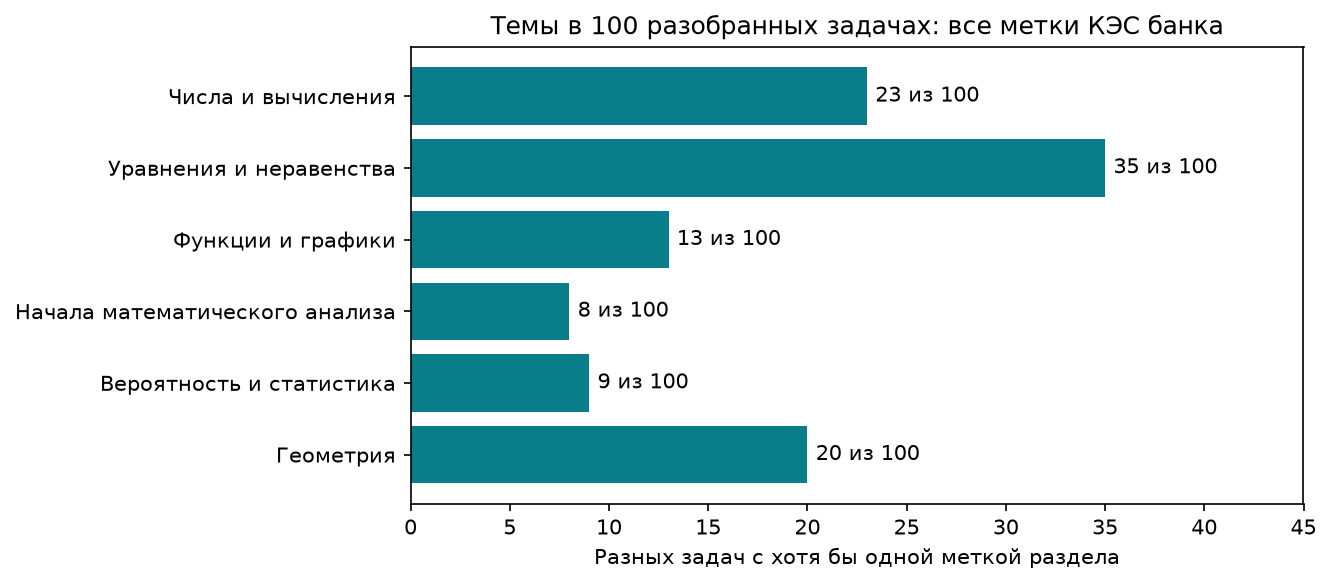

**Результат.** Числа и вычисления — 23; Уравнения и неравенства — 35; Функции и графики — 13; Начала математического анализа — 8; Вероятность и статистика — 9; Геометрия — 20. Сумма столбцов может превышать 100: межтематические задачи учитываются в нескольких разделах. Это распределение наших материалов по содержанию банка, а не число разных навыков.

In [6]:
import csv
import textwrap
import report_fipi_extension as topic_report
topic_labels={'1':'Числа и вычисления','2':'Уравнения и неравенства','3':'Функции и графики',
              '4':'Начала математического анализа','5':'Множества и логика',
              '6':'Вероятность и статистика','7':'Геометрия'}
bank_by_id={r['id']:r for r in bank}
topic_tasks=data['baseline']+data['new']
assert len(topic_tasks)==100
def task_topics(tid):
    return {v.split()[0].split('.')[0] for m in bank_by_id[tid]['metadata'] if m['label']=='КЭС:' for v in m['values']}
topic_codes=sorted({g for r in bank for m in r['metadata'] if m['label']=='КЭС:' for v in m['values'] for g in [v.split()[0].split('.')[0]]},key=int)
assert set(topic_codes)<=set(topic_labels)
assert all(task_topics(r['task_id']) for r in topic_tasks)
topic_memberships=[{'task_id':r['task_id'],'topic_code':g,'topic':topic_labels[g],'included':r['included']}
                   for r in topic_tasks for g in sorted(task_topics(r['task_id']),key=int)]
topic_counts=Counter(r['topic_code'] for r in topic_memberships)
def save_topic_table(filename,rows):
    with (OUT/filename).open('w',encoding='utf-8-sig',newline='') as stream:
        writer=csv.DictWriter(stream,fieldnames=list(rows[0]));writer.writeheader();writer.writerows(rows)
save_topic_table('topic-memberships-100.csv',topic_memberships)
save_topic_table('topic-distribution-100.csv',[{'topic_code':g,'topic':topic_labels[g],'tasks':topic_counts[g],'sample_size':100} for g in topic_codes])
fig,ax=plt.subplots(figsize=(9,4))
values=[topic_counts[g] for g in topic_codes]
bars=ax.barh([topic_labels[g] for g in topic_codes],values,color='#087e8b')
ax.bar_label(bars,labels=[f'{n} из 100' for n in values],padding=4)
ax.invert_yaxis();ax.set_xlim(0,max(values)+10)
ax.set_xlabel('Разных задач с хотя бы одной меткой раздела')
ax.set_title('Темы в 100 разобранных задачах: все метки КЭС банка')
chart('09-topic-distribution')
display(Markdown('**Результат.** '+ '; '.join(f'{topic_labels[g]} — {topic_counts[g]}' for g in topic_codes)+'. Сумма столбцов может превышать 100: межтематические задачи учитываются в нескольких разделах. Это распределение наших материалов по содержанию банка, а не число разных навыков.'))

## 4. Как устроены разборы: сколько шагов и KC содержит задача

В исходных файлах есть 100 разборов. Для подсчёта повторяемости действий использованы 98 - по 49 из каждой части. Две задачи сохранены, но не участвуют в основных частотах:

- **eFF32e:** геометрический разбор получился условным. Ответ зависит от того, допускает ли формулировка совпадение точки пересечения с вершиной. Для одного прочтения найден контрпример; дальнейшее решение использует дополнительное условие о внутренней точке ребра.
- **C41083:** при вычислении вероятности автор использовал независимость выстрелов, а аудитор счёл это предположение недостаточно обоснованным условием.

Исключение означает, что эти разборы не используются как обычные завершённые примеры при подсчёте KC. Число 98 описывает объём включённых данных, а не долю правильных решений: оставшиеся задачи не проходили сплошную проверку преподавателем.

**Откуда берутся показатели ниже.** Для каждого разбора считаем длину списка `steps` и число записей `kc_candidates`. Один шаг может быть связан с несколькими KC; один KC может использоваться в нескольких шагах. Поэтому число шагов и число описаний умений не обязаны совпадать. После этого группируем задачи по части выборки и формату ответа и считаем медианы - значения в середине упорядоченного ряда. В таблице также показано, сколько определений общего каталога встретилось хотя бы в одной задаче и сколько встретилось ровно в одной.

**Как читать распределение шагов.** На каждом из двух графиков по горизонтали указано число шагов в разборе, по вертикали - число задач такой длины. Например, столбец над значением 3 показывает количество задач, разобранных на три шага. Так видно, сосредоточены ли разборы около нескольких действий или заметную часть составляют длинные решения.

| Слой | Разборов | В частотах | Определений KC с назначениями | Встречаются только в одной задаче |
|---|---|---|---|---|
| Первые 50 | 50 | 49 | 136 | 101/136 |
| Дополнительные 50 | 50 | 49 | 48 | 30/48 |
| Все 100 | 100 | 98 | 138 | 76/138 |

| Слой | Формат | Задач | Медиана шагов | Медиана кандидатов KC |
|---|---|---|---|---|
| Первые 50 | Краткий ответ | 29 | 2 | 3 |
| Первые 50 | Развернутый ответ | 20 | 4.0 | 5.0 |
| Дополнительные 50 | Краткий ответ | 30 | 3.0 | 3.0 |
| Дополнительные 50 | Развернутый ответ | 19 | 5 | 5 |

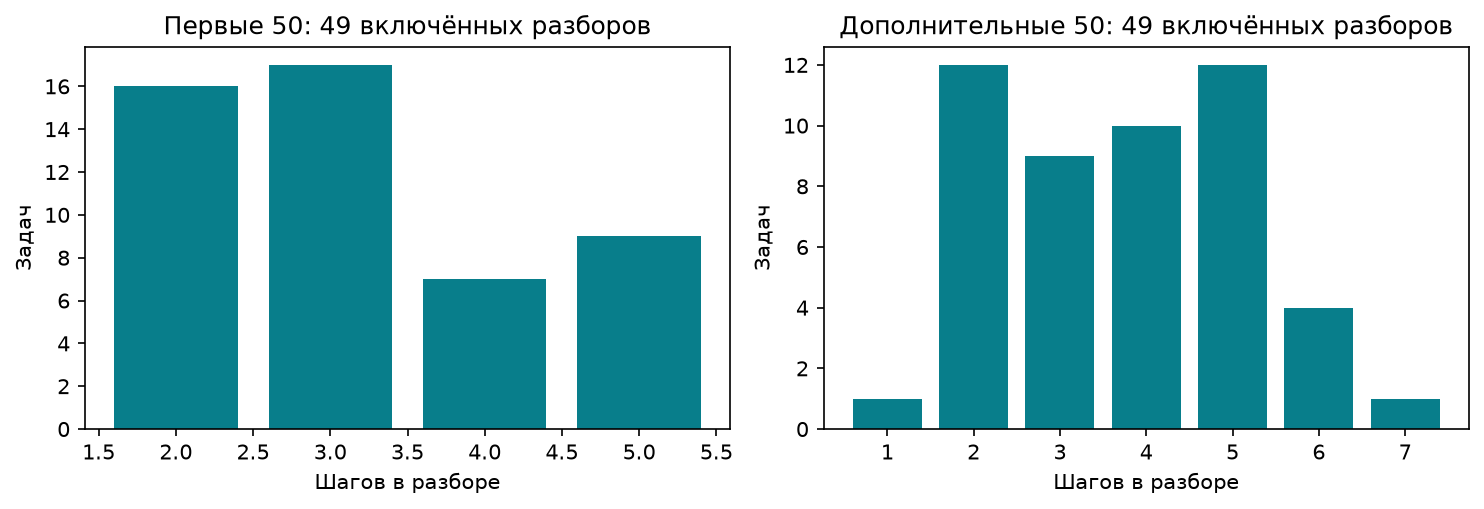

In [7]:
keys=[('baseline50','Первые 50'),('new_accumulated','Дополнительные 50'),('mixed_cumulative','Все 100')]
table([{'Слой':label,'Разборов':summary[k]['selected_n'],'В частотах':summary[k]['included_n'],
        'Определений KC с назначениями':summary[k]['confirmed_catalog_nodes'],
        'Встречаются только в одной задаче':f"{summary[k]['singleton_nodes']['numerator']}/{summary[k]['singleton_nodes']['denominator']}"} for k,label in keys])
table([{'Слой':label,'Формат':typ,'Задач':summary[k]['structure'][typ]['steps']['n'],
        'Медиана шагов':summary[k]['structure'][typ]['steps']['median'],
        'Медиана кандидатов KC':summary[k]['structure'][typ]['kc_candidates']['median']}
       for k,label in keys[:2] for typ in ['Краткий ответ','Развернутый ответ']])
fig,axes=plt.subplots(1,2,figsize=(10,3.5))
for ax,(k,label) in zip(axes,keys[:2]):
    dist=summary[k]['structure']['all']['steps']['distribution'];xs=sorted(map(int,dist))
    ax.bar(xs,[dist[str(x)] for x in xs],color='#087e8b');ax.set_title(label+': 49 включённых разборов');ax.set_xlabel('Шагов в разборе');ax.set_ylabel('Задач')
chart('03-step-counts')

**Что получилось.** Во всех первых 50 разборах сохранены 162 шага и 204 описания KC; в дополнительных 50 - 185 шагов и 199 описаний. Эти суммы включают и две задачи, исключённые из основных частот. Графики и медианы выше относятся к включённым 49+49.

У первых 49 разборов медианное число шагов равно 3, у дополнительных - 4. При этом медианное число кандидатов KC в обеих частях равно 4. То есть дополнительные решения записаны несколько более длинными последовательностями, но число выделенных описаний умений в середине распределения осталось тем же.

Формат ответа также связан с длиной записи решения. Для кратких ответов медиана шагов равна 2 в первой части и 3 во второй; для развёрнутых - 4 и 5. Медианное число KC равно соответственно 3 и 5 в обеих частях. Развёрнутые задачи в этих данных обычно описаны большим числом действий и умений. Это характеристика сохранённых разборов: длина зависит и от задачи, и от того, насколько подробно автор разделяет решение на шаги.

**Что это даёт проекту.** Один итоговый ответ скрывает несколько разных действий. Пошаговое представление позволяет связать отдельный результат с конкретным действием, а методы - собрать эти действия в маршрут. При этом количество записанных шагов само по себе не является оценкой сложности задачи: более подробное описание может увеличить его без изменения математики.

## 5. Какие действия повторяются между задачами

**Зачем считаем повторяемость.** Если одинаковое действие встречается в задачах разных тем, его можно использовать как дополнительный признак для поиска упражнений. Для этого сначала связываем локальные описания KC с общими определениями каталога. В частоты попадают только сохранённые связи, принятые по правилам сопоставления. Кандидаты без однозначного соответствия рассматриваются отдельно в разделе 6.

**Как устроен расчёт.** Из каждой включённой задачи берём множество ID каталога, с которыми связаны её действия. Для каждого ID считаем число разных задач, где он встретился. Несколько применений одного KC внутри одной задачи учитываются один раз. Например, частота 12 для линейного уравнения означает 12 задач с таким назначением, а не 12 уравнений или 12 ученических попыток.

**Как читать таблицу и график.** Таблица содержит десять наиболее частых определений среди 98 задач. На графике показаны восемь из них: K1-K8 - короткие обозначения, их расшифровка находится под графиком. Для каждого KC сравниваются доли задач в первых 49, дополнительных 49 и во всех 98. Высота 10% означает, что примерно одна из десяти включённых задач соответствующей группы имеет связь с этим определением. Сравнение показывает, какие действия повторно появились после расширения корпуса.

| KC | Действие | Задач / 98 |
|---|---|---|
| linear_equation | Решать линейное уравнение с числовыми коэффициентами | 12 |
| literal_9698b97fef22 | Преобразовывать рациональное уравнение с учётом знаменателей | 9 |
| graph_coordinates | Считывать координаты отмеченной точки с графика | 7 |
| graph_intersection | Сводить пересечение графиков к равенству значений | 7 |
| literal_c840012ba3dd | Отбирать алгебраические решения по условиям модели | 7 |
| pythagoras | Находить длину по теореме Пифагора | 7 |
| zero_product | Решать уравнение через нулевое произведение | 7 |
| set_intersection | Пересекать множества допустимых значений | 6 |
| literal_7baedb55a81a | Устанавливать область определения логарифмического выражения | 5 |
| quadratic_discriminant | Находить корни квадратного уравнения через дискриминант | 5 |

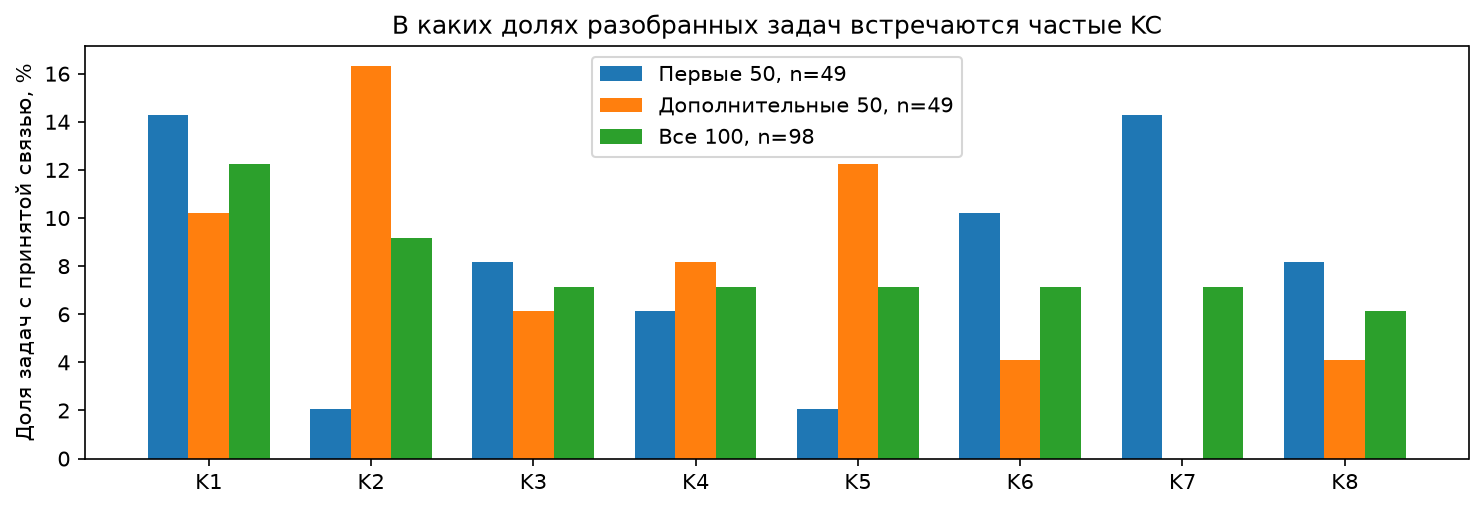

| Метка | Определение |
|---|---|
| K1 | Решать линейное уравнение с числовыми коэффициентами |
| K2 | Преобразовывать рациональное уравнение с учётом знаменателей |
| K3 | Считывать координаты отмеченной точки с графика |
| K4 | Сводить пересечение графиков к равенству значений |
| K5 | Отбирать алгебраические решения по условиям модели |
| K6 | Находить длину по теореме Пифагора |
| K7 | Решать уравнение через нулевое произведение |
| K8 | Пересекать множества допустимых значений |

In [8]:
freq=[r for r in tables['frequencies'] if r['population']=='mixed_cumulative']
top=sorted(freq,key=lambda r:(-r['task_n'],r['catalog_kc_id']))[:10]
table([{'KC':r['catalog_kc_id'],'Действие':names[r['catalog_kc_id']],'Задач / 98':r['task_n']} for r in top])
topids=[r['catalog_kc_id'] for r in top[:8]]
labels=[f'K{i+1}' for i in range(len(topids))]
fig,ax=plt.subplots(figsize=(10,3.5));x=np.arange(len(topids))
for j,(k,label) in enumerate(keys):
    f={r['catalog_kc_id']:r['task_n'] for r in tables['frequencies'] if r['population']==k}
    ax.bar(x+(j-1)*.25,[f.get(cid,0)/summary[k]['included_n']*100 for cid in topids],.25,label=label+f", n={summary[k]['included_n']}")
ax.set_xticks(x,labels);ax.set_ylabel('Доля задач с принятой связью, %');ax.legend();ax.set_title('В каких долях разобранных задач встречаются частые KC')
chart('04-frequencies')
table([{'Метка':lab,'Определение':names[cid]} for lab,cid in zip(labels,topids)])

**Какие повторения нашли.** Линейное уравнение связано с 12 из 98 задач: семь из первой части и пять из дополнительной. В первых разборах оно появляется в задачах на графики, показательные и логарифмические уравнения, геометрию, физическую формулу и проценты (`7D21DC`, `B948D4`, `19FBCF`, `F2A2EB`, `c15c1c`, `517970`, `6D1598`). Это содержательная связь между разными задачами: при разных условиях в решении возникает одно и то же действие. Такие примеры дают материал для практики действия в нескольких контекстах. Подготовка к нему и его роль в полном решении могут различаться - это разобрано на примерах в разделе 8.

**Что изменилось после добавления 50 задач.** Число определений каталога, встретившихся хотя бы в одной задаче, увеличилось со 136 до 138. При этом каталог остался прежним - 144 определения. Доля определений, связанных только с одной задачей, снизилась с 101/136 (74,3%) до 76/138 (55,1%). Значит, расширение преимущественно добавило примеры к уже встречавшимся определениям, а не только новые одиночные случаи. Это делает межзадачные связи более наполненными примерами; полнота самих сопоставлений рассматривается отдельно.

### Какие действия встречаются вместе и как соединены в маршруте

Частота показывает распространённость отдельного действия. Теперь задаём два других вопроса: **какие действия нужны в одной задаче** и **какие следуют друг за другом в сохранённом решении**.

**Совместная встречаемость.** Для каждой задачи берём все пары разных назначенных KC и считаем, в скольких задачах встретилась каждая пара. Клетка матрицы на пересечении K1 и K2 содержит это число. На диагонали стоит частота одного KC; матрица симметрична, потому что совместное присутствие не задаёт порядок. Метки K1-K8 имеют ту же расшифровку, что на предыдущем графике. Чем темнее клетка, тем больше задач содержит оба действия.

**Переходы в методе.** По списку `step_ids` каждого сохранённого Method берём соседние шаги и связываем назначенные им KC. Одинаковый переход несколько раз внутри задачи учитываем один раз; переходы KC в себя пропускаем. Действия внутри одного шага не упорядочиваем и независимые методы не соединяем. Таблица под матрицей показывает наиболее частые пары «из действия → в действие» в записанных маршрутах.

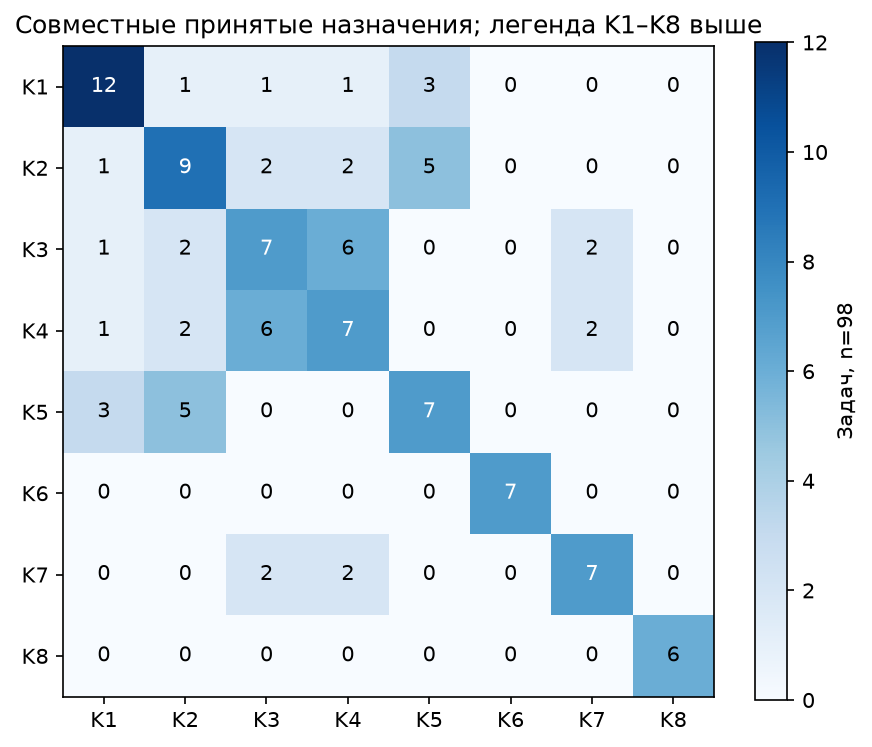

| Из | В | Задач / 98 |
|---|---|---|
| Восстанавливать прямую пропорциональность по точке | Сводить пересечение графиков к равенству значений | 3 |
| Преобразовывать рациональное уравнение с учётом знаменателей | Находить корни квадратного уравнения через дискриминант | 3 |
| Восстанавливать линейную функцию по двум точкам | Сводить пересечение графиков к равенству значений | 3 |
| Находить корни квадратного уравнения через дискриминант | Отбирать алгебраические решения по условиям модели | 3 |
| Восстанавливать прямую пропорциональность по точке | Решать уравнение через нулевое произведение | 2 |
| Решать простейшее тригонометрическое уравнение | Отбирать периодические корни на заданном промежутке | 2 |
| Строить равновозможную модель случайного выбора | Вычислять вероятность по числу равновозможных исходов | 2 |
| Сводить показательное уравнение к равенству показателей | Решать линейное уравнение с числовыми коэффициентами | 2 |

In [9]:
co={(r['kc_a'],r['kc_b']):r['task_n'] for r in tables['cooccurrence'] if r['population']=='mixed_cumulative'}
f={r['catalog_kc_id']:r['task_n'] for r in freq}
matrix=np.array([[f[a] if a==b else co.get(tuple(sorted((a,b))),0) for b in topids] for a in topids])
fig,ax=plt.subplots(figsize=(6,5));im=ax.imshow(matrix,cmap='Blues');ax.set_xticks(range(len(labels)),labels);ax.set_yticks(range(len(labels)),labels)
for i in range(len(labels)):
    for j in range(len(labels)):ax.text(j,i,str(matrix[i,j]),ha='center',va='center',color='white' if matrix[i,j]>matrix.max()/2 else 'black')
fig.colorbar(im,ax=ax,label='Задач, n=98');ax.set_title('Совместные принятые назначения; легенда K1–K8 выше')
chart('05-cooccurrence')
trans=sorted([r for r in tables['transitions'] if r['population']=='mixed_cumulative'],key=lambda r:-r['task_n'])[:8]
table([{'Из':names[r['from_kc']],'В':names[r['to_kc']],'Задач / 98':r['task_n']} for r in trans])

**Что видно на данных.** Считывание координат с графика и сведение пересечения графиков к равенству значений назначены вместе в шести задачах. Это два разных действия внутри одной группы упражнений: одно описывает чтение данных с рисунка, другое - математическое условие пересечения. В таблице переходов восстановление прямой пропорциональности по точке → сведение пересечения графиков к равенству значений встречается в трёх задачах.

**Как использовать этот результат.** Такие сочетания помогают разбирать упражнение на отдельные цели: чтение данных с графика, восстановление функции, составление уравнения пересечения. В будущем это позволит различать, на каком действии нужна помощь, и искать упражнения с нужным сочетанием действий. Здесь получены связи из записанных решений, а не результаты диагностики ученика.

Матрица отвечает на вопрос «встречаются ли действия вместе», а таблица - «в каком порядке они записаны в этих методах». Ни то ни другое не устанавливает обязательный порядок обучения: у задачи могут быть другие способы решения. Нулевая клетка также означает только отсутствие принятой пары в этих 98 разборах - действие могло не попасть в каталог или остаться без назначения.

### Какие KC связывают разные разделы ФИПИ

Соединяем по ID задачи её метки банка и принятые назначения KC. Строка матрицы - действие, столбец - раздел; число в клетке показывает, в скольких включённых задачах этого раздела встречается действие. Показаны 12 наиболее частых KC из 98 задач. Под названием раздела указан его объём среди этих 98. Каждую пару «задача - KC» считаем один раз внутри раздела.

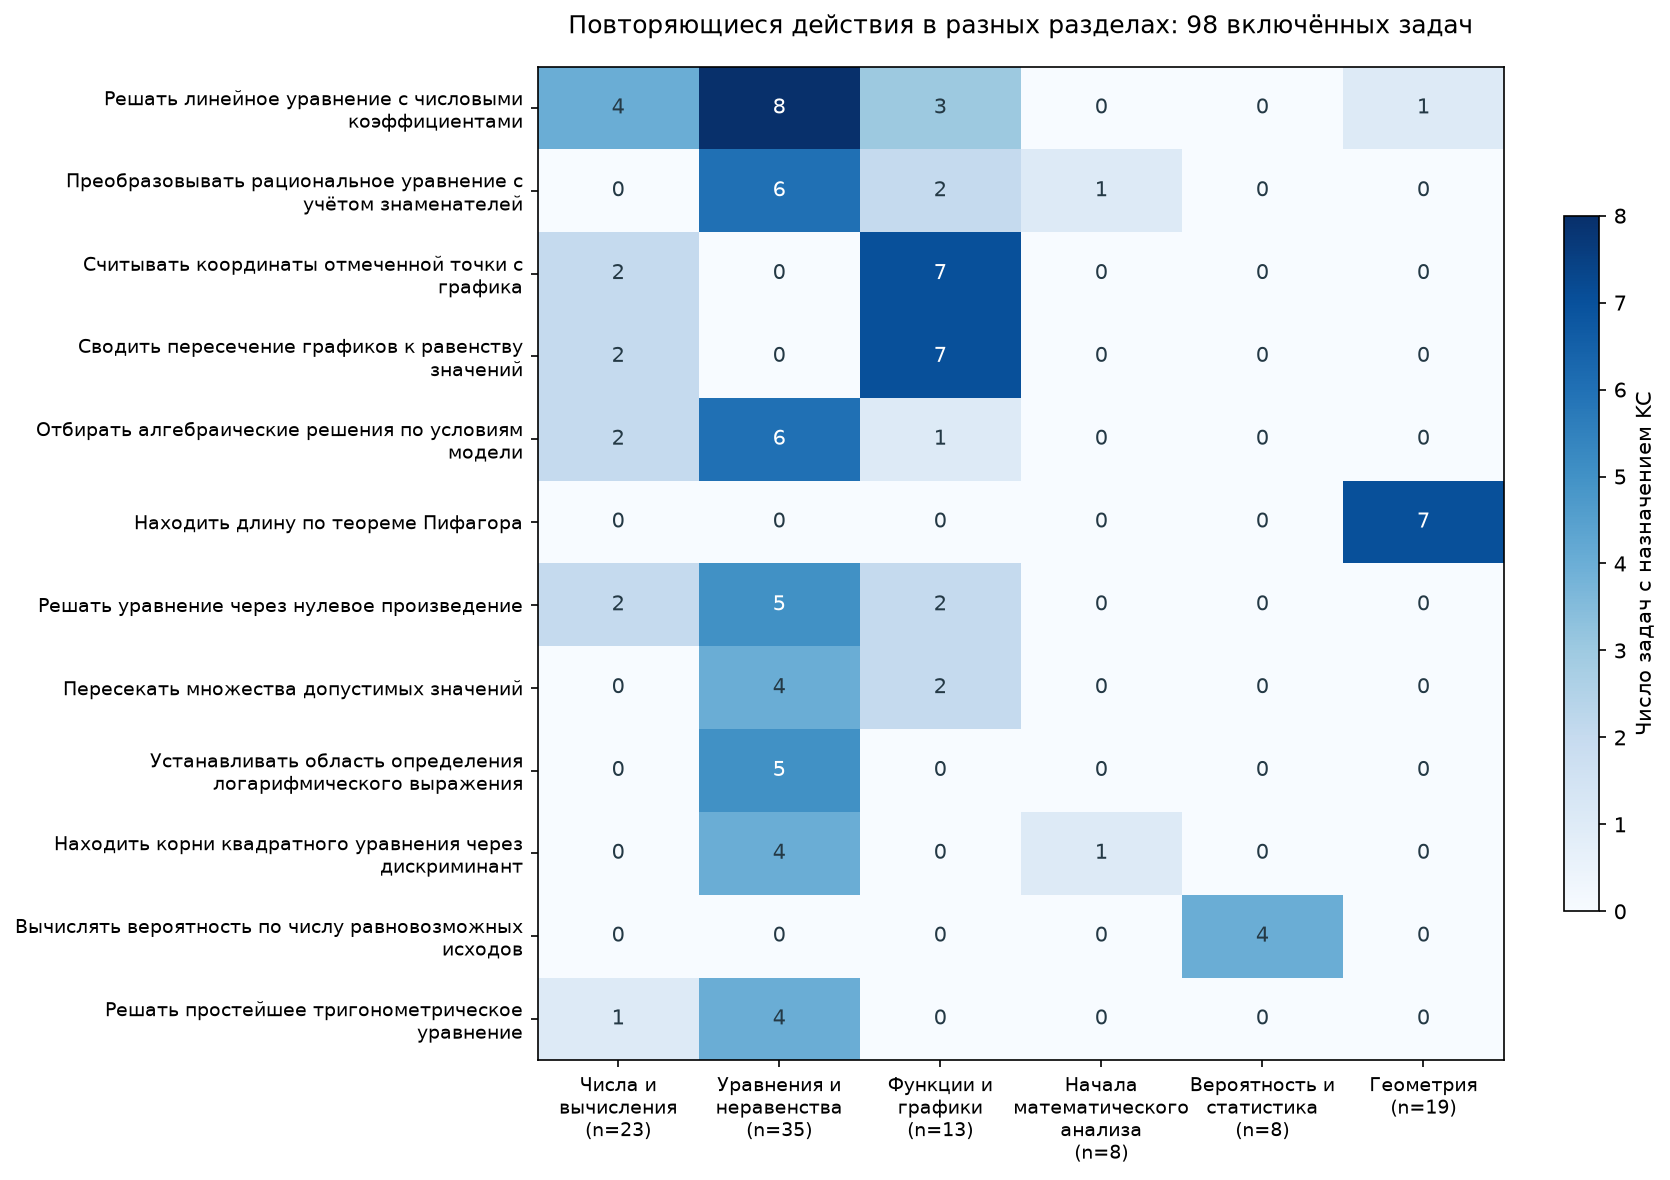

**Пример чтения.** Линейное уравнение назначено в 12 разных задачах; по разделам: Числа и вычисления — 4; Уравнения и неравенства — 8; Функции и графики — 3; Геометрия — 1. Одно задание может иметь метки нескольких разделов, поэтому сумма этих клеток может быть больше 12.

In [10]:
topic_assignments={(a['task_id'],a['local_id']):a['canonical_id'] for a in data['catalog']['assignments']}
topic_included=[r for r in topic_tasks if r['included']]
assert len(topic_included)==98
topic_links=[]
for row in topic_included:
    accepted=set(topic_report.mapping(row,topic_assignments).values())
    for group in sorted(task_topics(row['task_id']),key=int):
        for cid in sorted(accepted):
            topic_links.append({'task_id':row['task_id'],'topic_code':group,'topic':topic_labels[group],
                                'catalog_kc_id':cid,'kc_name':names[cid]})
assert len(topic_links)==len({(r['task_id'],r['topic_code'],r['catalog_kc_id']) for r in topic_links})
save_topic_table('task-topic-kc-98.csv',topic_links)
topic_denominators=Counter(g for r in topic_included for g in task_topics(r['task_id']))
topic_pair_counts=Counter((r['topic_code'],r['catalog_kc_id']) for r in topic_links)
save_topic_table('topic-kc-98.csv',[{'topic_code':g,'topic':topic_labels[g],'catalog_kc_id':cid,'kc_name':names[cid],
                                  'tasks':topic_pair_counts[(g,cid)],'topic_tasks':topic_denominators[g]}
                                 for cid in sorted(names) for g in topic_codes if topic_pair_counts[(g,cid)]])
topic_top=[r['catalog_kc_id'] for r in sorted(freq,key=lambda r:(-r['task_n'],r['catalog_kc_id']))[:12]]
topic_matrix=np.array([[topic_pair_counts[(g,cid)] for g in topic_codes] for cid in topic_top])
fig,ax=plt.subplots(figsize=(12,8))
im=ax.imshow(topic_matrix,cmap='Blues',aspect='auto',vmin=0)
ax.set_yticks(range(len(topic_top)),[textwrap.fill(names[cid],45) for cid in topic_top])
ax.set_xticks(range(len(topic_codes)),[textwrap.fill(topic_labels[g],16)+f'\n(n={topic_denominators[g]})' for g in topic_codes])
ax.tick_params(axis='both',labelsize=9)
for i in range(len(topic_top)):
    for j in range(len(topic_codes)):
        n=topic_matrix[i,j]
        ax.text(j,i,str(n),ha='center',va='center',color='white' if n>topic_matrix.max()/2 else '#243945',fontsize=10)
fig.colorbar(im,ax=ax,label='Число задач с назначением KC',shrink=.7)
ax.set_title('Повторяющиеся действия в разных разделах: 98 включённых задач',pad=16)
chart('10-topic-kc')
linear_topics=[g for g in topic_codes if topic_pair_counts[(g,'linear_equation')]]
display(Markdown('**Пример чтения.** Линейное уравнение назначено в 12 разных задачах; по разделам: '+
    '; '.join(f'{topic_labels[g]} — {topic_pair_counts[(g,"linear_equation")]}' for g in linear_topics)+
    '. Одно задание может иметь метки нескольких разделов, поэтому сумма этих клеток может быть больше 12.'))

**Смысл результата.** Заполненные клетки одной строки в нескольких столбцах показывают материал для тренировки действия в разных темах. Сочетания в одном столбце помогают искать упражнения внутри раздела по более точной цели, чем название темы. У разделов разные объёмы, поэтому числа читаем вместе с `n`, а ноль - как отсутствие принятого назначения в текущих разборах. Связь получена через конкретные задачи, а не через приравнивание темы ФИПИ к навыку.

## 6. Как каталог описывает действия из дополнительных задач

**Зачем нужен этот этап.** Автор разбора описывает действия своими словами. Чтобы посчитать повторения между задачами, нужно определить, какие из этих описаний относятся к одному умению. Иначе одинаковая операция с разными названиями будет выглядеть как несколько разных KC, а похожие названия могут ошибочно объединить разные действия.

Для дополнительных 50 задач это сопоставление выполнял отдельный агент-аудитор. На вход он получал условие с рисунками, ответ автора со шагами и кандидатами KC, а также фиксированный каталог из 144 определений. Для каждого кандидата аудитор искал соответствующее определение, проверял свидетельства в шагах и условия применения действия. Решение сохранялось с цитатами и обоснованием.

**Четыре возможных результата:**

| Решение аудитора | Что означает | Как учитываем в частотах |
|---|---|---|
| Полное соответствие (`match`) | Действие и условия подходят к конкретному определению каталога | Связываем задачу с этим ID каталога, если весь разбор допущен к анализу |
| Новое предложение (`new_candidate`) | Подходящего определения в каталоге не найдено | Сохраняем описание отдельно; в частоту существующего KC оно не входит |
| Требует разделения (`needs_split`) | Одно авторское описание объединяет несколько действий | Сохраняем предложенные части и причины; не заменяем ими исходную разметку при подсчёте |
| Спорное соответствие (`uncertain`) | Контекста недостаточно либо несколько определений подходят неоднозначно | Сохраняем неопределённость вместо выбора ID без достаточных оснований |

**Что показывает график.** В дополнительных 50 разборах авторы выделили 199 кандидатов KC. Для каждого есть один статус аудитора; длина полосы показывает число кандидатов с этим статусом. Так проверяем, насколько существующий каталог подходит к новым описаниям действий и где возникают затруднения сопоставления.

Для связи с предыдущими частотами отдельно считаем показатели по допущенным 49 задачам: в них 197 кандидатов. Разница связана с исключением C41083, описанным в разделе 4. Общий результат аудита 50 задач и частоты по 49 отвечают на разные вопросы, поэтому их объёмы указаны явно.

| Статус | Кандидатов | Всего кандидатов |
|---|---|---|
| Полное соответствие | 87 | 199 |
| Новое предложение | 62 | 199 |
| Требует разделения | 41 | 199 |
| Спорное соответствие | 9 | 199 |

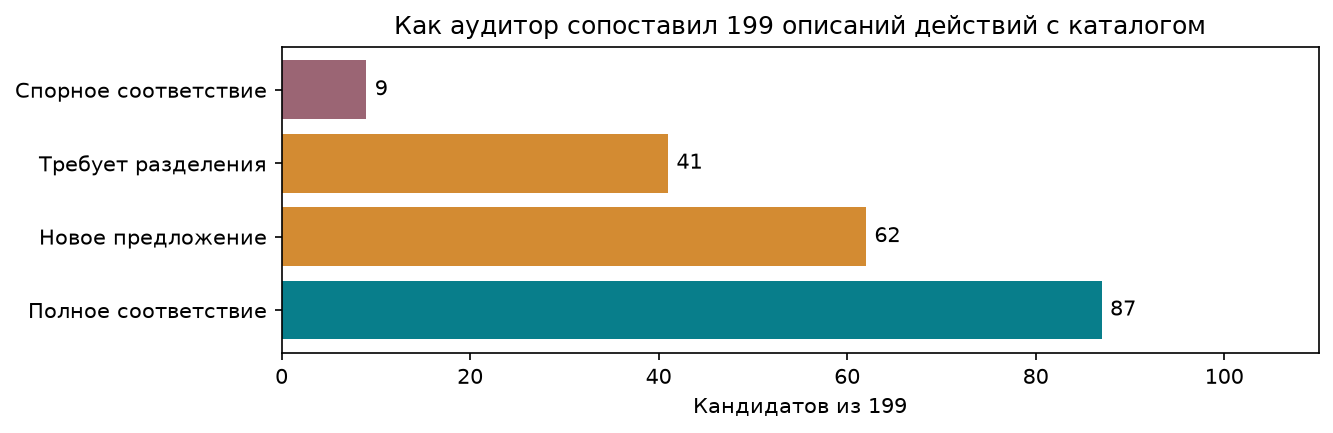

Без полного соответствия каталогу: 110 из 197 кандидатов (55.8%).
Хотя бы один такой кандидат есть в 45 из 49 включённых дополнительных задач.


In [11]:
new=summary['new_accumulated']
ru={'match':'Полное соответствие','new_candidate':'Новое предложение','needs_split':'Требует разделения','uncertain':'Спорное соответствие'}
table([{'Статус':ru[k],'Кандидатов':v['numerator'],'Всего кандидатов':v['denominator']} for k,v in new['audit_statuses'].items()])
fig,ax=plt.subplots(figsize=(9,3));vs=list(new['audit_statuses'].values())
bars=ax.barh([ru[k] for k in new['audit_statuses']],[v['numerator'] for v in vs],color=['#087e8b','#d38b32','#d38b32','#9b6574'])
ax.bar_label(bars,padding=4);ax.set_xlim(0,110);ax.set_xlabel('Кандидатов из 199');ax.set_title('Как аудитор сопоставил 199 описаний действий с каталогом')
chart('06-audit')
unmatched=new['unmatched_local_candidates']
print(f"Без полного соответствия каталогу: {unmatched['numerator']} из {unmatched['denominator']} кандидатов ({unmatched['numerator']/unmatched['denominator']:.1%}).")
print(f"Хотя бы один такой кандидат есть в {new['incomplete_mapping_tasks']} из {new['included_n']} включённых дополнительных задач.")

**Что получилось.** Из 199 описаний действий аудитор связал 87 с существующими определениями, для 62 предложил новые определения, 41 счёл составным и ещё для девяти оставил соответствие спорным. Значит, расширение выявило сразу несколько задач для работы с каталогом: добавить отсутствующие описания, уточнить детализацию составных действий и различить перекрывающиеся определения.

В 49 включённых дополнительных задачах полного соответствия нет у **110 из 197 кандидатов (55,8%)**. Хотя бы один такой случай есть в **45 из 49 задач**. Это не означает, что 45 решений ошибочны: речь о том, удалось ли связать все описанные действия с общими определениями. Поэтому частоты предыдущего раздела показывают только часть действий, уже сопоставленную с каталогом.

62 новых предложения также не означают 62 разных новых умения: одинаковое действие могло быть предложено в нескольких задачах. Здесь они ещё не объединялись между собой.

### Три примера: почему действие осталось без общего ID

Таблица ниже показывает сохранённые решения аудитора вместе с фрагментами шагов. Примеры выбраны, чтобы раскрыть три разные причины: составное описание, пересечение определений и предложение нового действия. Они помогают понять смысл статусов на графике.

In [12]:
examples=[('68Ac00','kc4'),('F6158A','kc1'),('F6158A','kc2')]
rows=[]
for tid,kid in examples:
    r=next(r for r in data['new'] if r['task_id']==tid)
    d=next(d for d in r['audit']['decisions'] if d['local_kc_id']==kid)
    rows.append({'ID / KC':tid+'/'+kid,'Статус':d['status'],
                 'Свидетельство':' | '.join(e['quote'] for e in d['evidence']), 'Обоснование аудитора':d['rationale']})
table(rows)

| ID / KC | Статус | Свидетельство | Обоснование аудитора |
|---|---|---|---|
| 68Ac00/kc4 | needs_split | x(x−5)=0, откуда x=0 или x=5. На рисунке A — начало координат, поэтому абсцисса другой точки B равна 5. | Кандидат явно соединяет решение уравнения и соотнесение корней с именованными точками пересечения. Нельзя весь составной кандидат приравнять к zero_product. Арифметику линейного множителя отдельно не дроблю. |
| F6158A/kc1 | uncertain | cos(2α)=1−2sin²α=1−2·0,2²=0,92. | Применение cos(2α)=1−2sin²α и вычисление по данному синусу наблюдаются непосредственно; знания четверти действительно не требуется. Числовая подстановка завершает то же действие и сама по себе не требует дробления. Однако два предварительных определения тригонометрического преобразования перекрываются и не дают обоснованного единственного ID; поэтому соответствие не подтверждено как match. |
| F6158A/kc2 | new_candidate | 3cos(2α)=3·0,92=2,76. | По предыдущему шагу известен косинус 0,92; в текущем шаге выполняется единственное числовое умножение на заданный коэффициент 3. Полный каталог не содержит определения именно этой арифметической операции. Сюжет с косинусом не меняет её границы. |

- **68Ac00/kc4:** составной кандидат соединяет нулевое произведение и выбор корня для именованной точки. Первое действие знакомо, но весь кандидат не совпадает с одним определением; отдельное назначение `zero_product` не добавлялось.
- **F6158A/kc1:** операция видна, однако два определения тригонометрического преобразования перекрываются; нет обоснованного единственного ID.
- **F6158A/kc2:** аудитор предлагает отдельное числовое умножение. Это иллюстрирует вопрос полезной детализации, а не автоматически одобренный новый навык.

**Что это меняет в работе с данными.** При расширении появляются дополнительные примеры знакомых KC, но одновременно обнаруживаются действия, которые текущая система определений описывает неудобно. Эти случаи полезно разбирать по условиям и шагам: уточнять составные формулировки, различать близкие определения и объединять повторяющиеся новые предложения. Исходные вердикты сохранены, поэтому будущую редакцию каталога можно будет сравнить с текущей на тех же задачах.

## 7. Как проверяли дополнительные разборы и что обнаружили

**Как устроена проверка.** Дополнительные 50 задач обрабатывались партиями 15+15+15+5. Автор получал условие и готовил разбор; отдельный аудитор проверял сопоставления KC и отмечал замеченные проблемы решения. Скрипты проверяли структуру ответов, ID, ссылки между шагами и KC и сохранность входных материалов. Между партиями выполнялись контроль комплектности и выборочные содержательные проверки.

Это разные виды контроля: корректный JSON означает, что файл можно обработать; обоснованное назначение KC связывает действие с определением; математическая проверка устанавливает, что само действие и результат верны. Сбой на одном уровне может остаться незаметным на другом. Ниже - конкретные случаи, обнаруженные при подготовке корпуса.

| Случай | Наблюдение в сохранённых материалах | Следствие для будущего тьютора |
|---|---|---|
| F416AF | Автор прочёл AM=BN=3 как 1; первый аудитор пропустил. Контрольный расчёт выявил расхождение; отдельная исправленная попытка дала 2√3 | Нужен отдельный контроль чтения источника. Согласие автора и аудитора недостаточно |
| C41083 | Предположение независимости выстрелов сочтено блокирующим; задача исключена | Правило допуска модельных предположений нужно согласовать заранее |
| F3F0DF | Сходная ситуация принята другим аудитором с оговорённой моделью; задача включена | Порог допуска ещё неодинаков; частоты зависят от вердиктов |
| eFF32e | Исторический partial с вопросом K=S сохранён | Неоднозначность требует предметного разбора, не принудительного ответа |

**Что удалось исправить.** Для F416AF сохранены первоначальные и исправленные разборы и аудиты. После указания на ошибку чтения автор подготовил новую попытку. В основные частоты вошла исправленная версия; остальные 48 включённых дополнительных задач имеют первоначальные авторские ответы. История попыток позволяет увидеть, что именно изменилось, вместо незаметной замены исходного файла.

**Что показали случаи с вероятностью.** C41083 и F3F0DF обнажили различие в допустимости предположения о независимости: в одном случае оно заблокировало включение, в другом было принято с оговоркой. Поэтому единообразие правил аудита важно для самих метрик - от решения о допуске зависит, какие действия попадут в частоты.

**Вывод для прототипа.** Перед использованием разбора как материала для объяснения или проверки ответа важно различать качество чтения условия, правильность решения и корректность метки KC. Согласие двух агентов не устраняет ошибку источника или одинаковое неверное прочтение. В текущем корпусе есть технические проверки, аудит дополнительных задач и выборочный содержательный контроль; это описывает фактически выполненную проверку, а не оценку процента правильных решений. [Подробный журнал и происхождение попыток](../../data/annotation/runs/2026-11-02-fipi-extension-150/README.md).

## 8. Как результаты разметки связаны с будущим тьютором

Частоты подтвердили конкретные повторения, но граф «задачи с одним KC» не объясняет, какие упражнения подходят для одной учебной цели. Поэтому дополнительно сравнили сами условия, вход в действие и то, какой результат требуется дальше.

**Метод продолжения:** все 12 включённых задач с принятым linear_equation описаны по одной явной рубрике: подготовка → установленное уравнение → действие → результат → ограничения и роль результата. Контексты и нормализованные уравнения — редакторские интерпретации основного ассистента, сохранённые отдельно от исходных назначений. Это не автоматическое извлечение, не новые решения модели и не экспертный эталон.

Для контрастов целенаправленно выбраны девять пар и два одиночных случая из 19 задач. Отбор и рубрика исследовательские, после просмотра. Сначала подготовлены смысловые входы и выполнен полный расчёт, затем выборочный визуальный просмотр; отдельного ослеплённого пилота не было. В этой сводке приведены три наиболее показательных сравнения. Качественные выводы нельзя распространять на весь банк как частотную оценку.

### А. Общее действие при разных условиях входа

**19FBCF:** найдите корень уравнения $3^{x+6}=9^{2x}$. В сохранённом s1 получено $x+6=4x$, затем в s2 — $x=2$.

**91CD43:** найдите корень уравнения $\log_5(8-x)=\log_5 2$. В s1 установлено $x<8$, в s2 получено $8-x=2$, затем в s3 — $x=6$ с проверкой допустимости.

Условия здесь переданы в Markdown с формулами; ID и сохранённые шаги позволяют сверить запись с источником. В обоих решениях есть линейное уравнение, но подготовка разная: приведение показателей против закона логарифма и ОДЗ. Если цель — только линейная операция, можно подготовить явно данное уравнение. Если предъявляем всю задачу, добавляются другие требования. Наличие одного KC не устанавливает подходящесть полного задания конкретному ученику.

### Б. Результат компонента и ответ задачи — разные величины

**D334F2, исходное условие:** в июле 2026 года берут кредит 177120 рублей, каждый январь долг увеличивается на 25%, с февраля по июнь выплачивается один платёж. Кредит погашают четырьмя равными платежами; требуется общая сумма выплат.

Сохранённая трасса: в s1 вводится рекуррентная модель $D_k=(5/4)D_{k-1}-x$, в s2 получается $1476x=110700000$, в s3 — платёж $x=75000$, в s4 — итог $4x=300000$ рублей. Это сокращённая передача полного условия и шагов, не новая задача.

В 19FBCF число 2 завершает исходный вопрос. В D334F2 число 75000 правильно для текущего компонента, но не отвечает на исходный вопрос об общей сумме. Значит, проверка должна знать **цель текущего действия** и сохранять связь с целью всей задачи. По одному числовому успеху нельзя засчитывать полный маршрут или освоение.

### В. Две задачи на пересечение графиков: общий маршрут при разной записи шагов

**02A17e и 87FAA1:** на рисунках даны функции $f(x)=k/x$ и $g(x)=ax+b$, пересекающиеся в A и B; требуется абсцисса B. Ниже — оригинальные изображения снимка, условия переданы с сохранением формы функций.

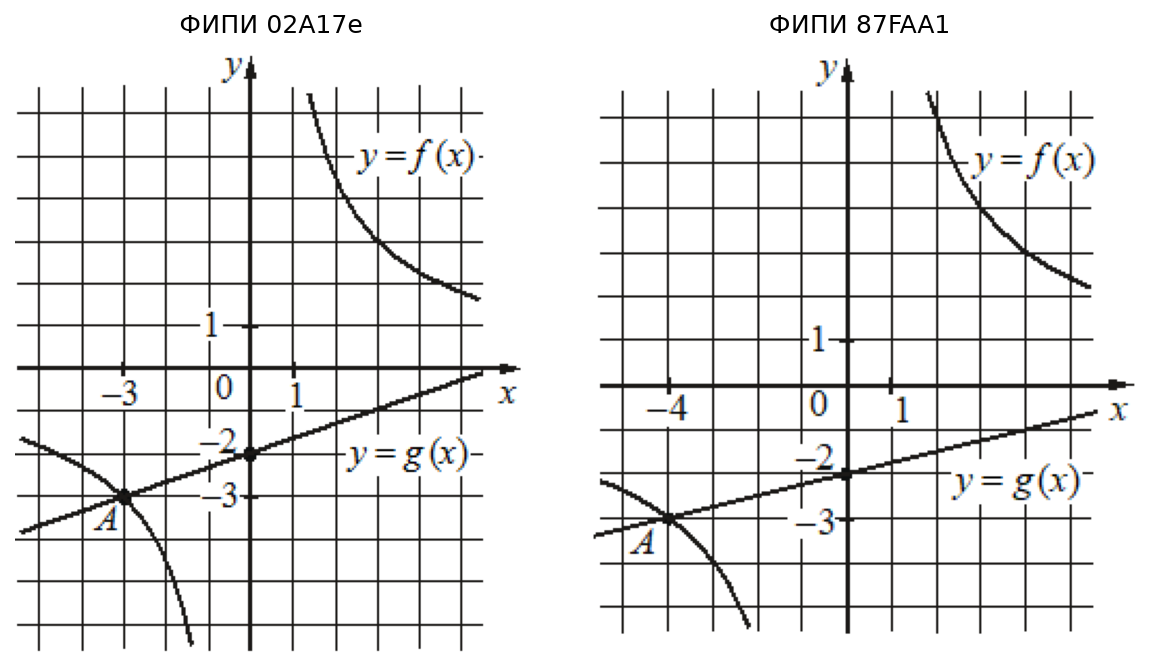

| Задача | После восстановления функций | Квадратное уравнение | Корни | Спрашиваемая абсцисса |
|---|---|---|---|---|
| 02A17e | 9/x=x/3−2, x≠0 | x²−6x−27=0 | −3 и 9 | 9 |
| 87FAA1 | 12/x=x/4−2, x≠0 | x²−8x−48=0 | −4 и 12 | 12 |

In [13]:
from PIL import Image as RasterImage
fig,axes=plt.subplots(1,2,figsize=(8,4.5))
for ax,tid in zip(axes,['02A17e','87FAA1']):
    inp=task_by_id[tid]['input'];asset=inp['assets'][0]
    with RasterImage.open(EXT/'inputs'/asset['path']) as im:
        ax.imshow(np.asarray(im.convert('RGBA')))
    ax.set_facecolor('white');ax.set_title('ФИПИ '+tid);ax.axis('off')
chart('07-original-graph-pair')
table([{'Задача':'02A17e','После восстановления функций':'9/x=x/3−2, x≠0','Квадратное уравнение':'x²−6x−27=0','Корни':'−3 и 9','Спрашиваемая абсцисса':'9'},
       {'Задача':'87FAA1','После восстановления функций':'12/x=x/4−2, x≠0','Квадратное уравнение':'x²−8x−48=0','Корни':'−4 и 12','Спрашиваемая абсцисса':'12'}])

Оба записанных метода восстанавливают формулы по рисунку, составляют равенство значений, решают квадратное уравнение и выбирают вторую точку. Однако в 02A17e решение и выбор записаны одним s5, а в 87FAA1 — s5 и s6. Поэтому число шагов зависит от оформления разметки, а не только от содержания или трудности.

Это кандидаты на близкую практику маршрута после предметной проверки. Их сходство также важно учитывать при будущем отделении примеров разработки от проверки: близкие варианты не являются сильным свидетельством переноса. Два просмотренных примера не устанавливают автоматически всё семейство банка.

### От общей метки KC к конкретному упражнению: разбор всех 12 задач

В разделе 5 линейное уравнение встретилось в 12 задачах разных тем. Три сопоставления выше объяснили, почему общий KC ещё не описывает всё упражнение: перед уравнением нужна подготовка, после него может требоваться дополнительное действие. Теперь проверяем это на **всех 12 задачах с назначением linear_equation**, а не только на выбранных примерах.

Для каждой задачи по сохранённому разбору выписали: где начинается решение линейного уравнения, что к этому моменту уже получено, какое уравнение решается и является ли найденное число итоговым ответом. Под «готовым уравнением» здесь понимаем явно записанное равенство с неизвестной в первой степени, например $x+6=4x$.

**Как читать график ниже.** Одна строка - одна задача. Длина полосы показывает, сколько записанных шагов находится **до шага с линейным уравнением**. Цвет отвечает на другой вопрос:

- **Бирюзовый:** нужное линейное уравнение уже получено в предыдущем шаге; можно отдельно рассмотреть его решение.
- **Охра:** в самом шаге ещё объединены подготовка и решение - например, подстановка в формулу, возведение в квадрат или сокращение квадратных членов.

Например, у 19FBCF сначала приравниваются показатели степеней, и лишь затем решается $x+6=4x$. У F2A2EB нужное линейное равенство появляется после сокращения квадратных членов внутри того же шага. Поэтому одинаковая метка KC ведёт к разной начальной ситуации. Длина полосы описывает оформление сохранённого решения, а цвет - готовность уравнения перед целевым действием; это не шкала трудности.

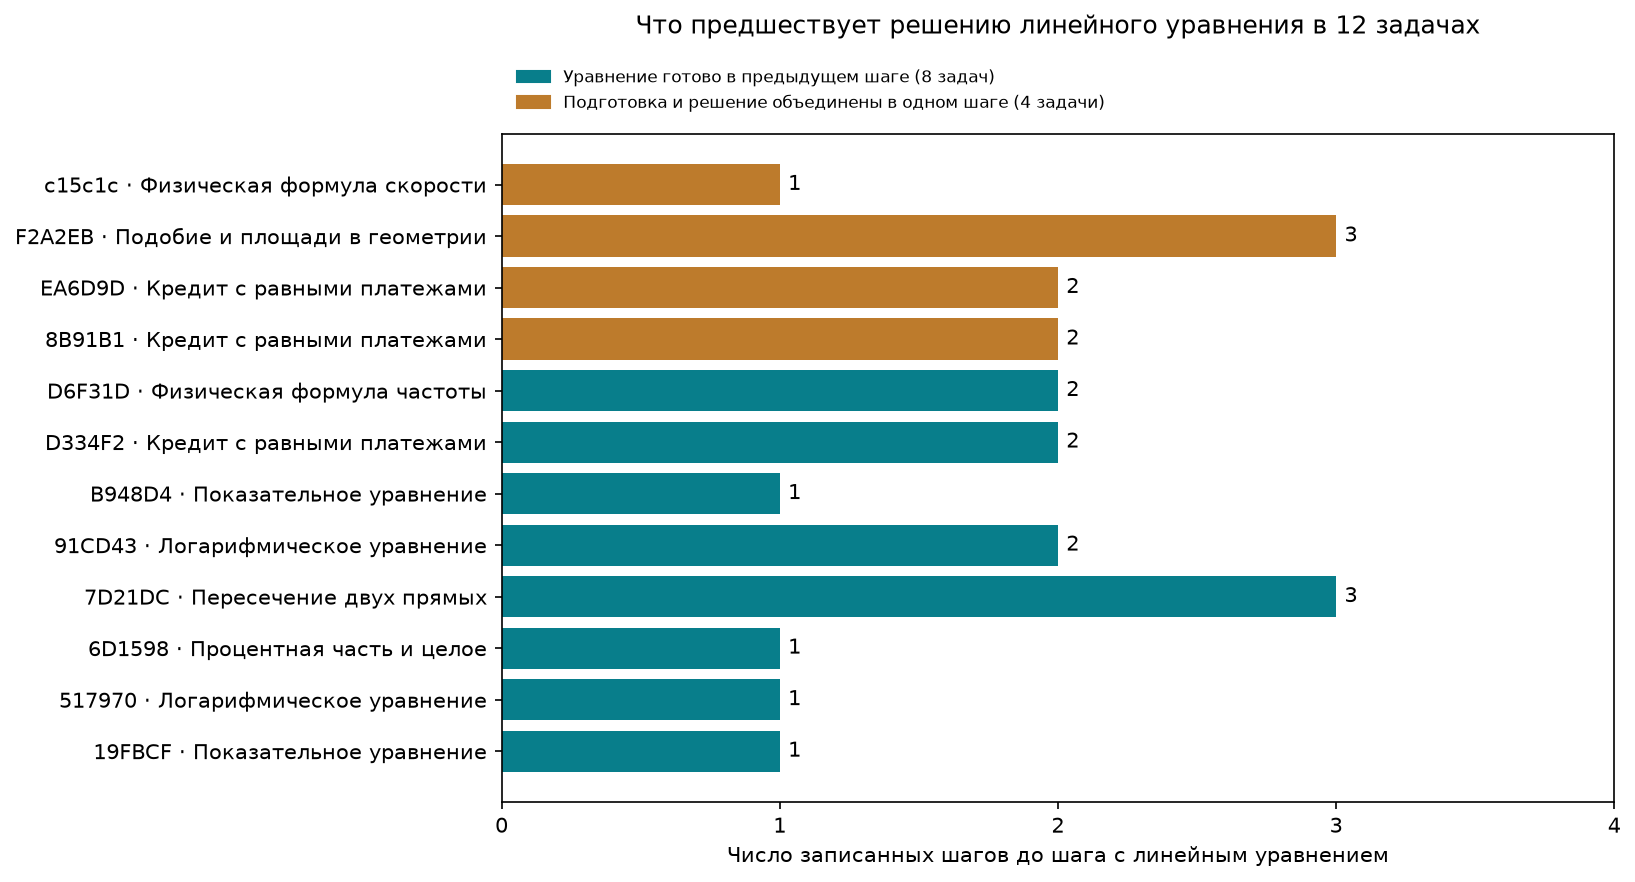

| ID | Контекст задачи | Уравнение, выделенное из разбора | Результат решения уравнения | Ответ всей задачи |
|---|---|---|---|---|
| 19FBCF | Показательное уравнение | x+6=4*x | 2 | 2 |
| B948D4 | Показательное уравнение | x-7=-3 | 4 | 4 |
| 517970 | Логарифмическое уравнение | x-2=11 | 13 | 13 |
| 91CD43 | Логарифмическое уравнение | 8-x=2 | 6 | 6 |
| 7D21DC | Пересечение двух прямых | x+3=2*x | 3 | 3 |
| 6D1598 | Процентная часть и целое | N/20=6 | 120 | 120 человек |
| D334F2 | Кредит с равными платежами | 1476*x=110700000 | 75000 | 300000 рублей |
| D6F31D | Физическая формула частоты | 10*c=3150 | 315 | 315 |
| 8B91B1 | Кредит с равными платежами | (1331/1000)*S-(331/100)*(S+40980)/3=0 | 198600 | 198600 рублей |
| EA6D9D | Кредит с равными платежами | (1331/1000)*(3*x-34150)-(331/100)*x=0 | 66550 | 199650 рублей |
| F2A2EB | Подобие и площади в геометрии | (5-e)**2=e**2-e+1 | 8/3 | а) углы равны; б) S(AEM):S(CMK)=4:9 |
| c15c1c | Физическая формула скорости | 14400=(3/5)*a | 24000 | 24000 км/ч² |

In [14]:
from matplotlib.patches import Patch
entry_cases=sorted(integrated['contracts'],key=lambda c:(c['entry_availability'],c['task_id']))
fig,ax=plt.subplots(figsize=(11,6))
entry_values=[c['saved_context_steps_before'] for c in entry_cases]
entry_colors=['#087e8b' if c['entry_availability']=='prior_step' else '#bd7b2c' for c in entry_cases]
bars=ax.barh([c['task_id']+' · '+c['context_label'] for c in entry_cases],entry_values,color=entry_colors)
ax.bar_label(bars,padding=4)
ax.set_xticks(range(max(entry_values)+2));ax.set_xlim(0,max(entry_values)+1)
ax.set_xlabel('Число записанных шагов до шага с линейным уравнением')
ax.set_title('Что предшествует решению линейного уравнения в 12 задачах',pad=48)
ax.legend(handles=[Patch(color='#087e8b',label='Уравнение готово в предыдущем шаге (8 задач)'),
                   Patch(color='#bd7b2c',label='Подготовка и решение объединены в одном шаге (4 задачи)')],
          loc='lower left',bbox_to_anchor=(0,1.01),fontsize=8,frameon=False)
chart('08-component-entry')
table([{'ID':c['task_id'],'Контекст задачи':c['context_label'],
        'Уравнение, выделенное из разбора':c['normalized_equation'],
        'Результат решения уравнения':c['exact_solution'],'Ответ всей задачи':c['whole_task_answer']}
       for c in integrated['contracts']])

**Что получилось.** В восьми задачах уравнение готово до целевого шага; в четырёх подготовка включена в этот же шаг. В семи целевых шагах автор назначил несколько KC - один записанный шаг нередко объединяет несколько действий. В трёх задачах результат решения линейного уравнения является промежуточной величиной. Это видно в таблице при сравнении двух последних столбцов: например, в D334F2 платёж равен 75000, а общая выплата - 300000.

**Как использовали исходную разметку.** В ней уже есть действия, результаты и ссылки на предыдущие шаги. Однако отдельного поля «готовое уравнение перед целевым действием» нет: иногда формула находится внутри длинного объяснения или получается после преобразования. Поэтому основной ассистент подготовил отдельные описания этих 12 случаев: выписал уравнение, подготовку, результат и его роль. Каждое описание связано с конкретными фрагментами исходного разбора; сами разборы и назначения KC сохранены без изменений. Так получен дополнительный слой описания учебного материала, который можно проверить по источникам.

### Зачем проверяли выписанные уравнения вычислительно

Чтобы использовать эти описания в проверке промежуточного ответа, важно убедиться, что выписанное равенство согласуется с указанным результатом. Для всех 12 уравнений коэффициенты представлены точными дробями; программно проверены приведение к линейному виду, единственность корня и совпадение с сохранённым числом.

Например, для 19FBCF из $x+6=4x$ получается $6-3x=0$, корень $x=2$; подстановка даёт $8=8$. В D334F2 аналогично проверяется уравнение для одного платежа, а общая выплата рассматривается отдельно. Для выбранных физических задач, кредитных моделей и двух задач на пересечение графиков дополнительно выполнены подстановки в исходные зависимости.

На этих уравнениях также проверен небольшой программный компонент: он получает **уже заданное уравнение и одно число**, затем проверяет равенство. В 60 программных пробах подаются ожидаемые ответы, неверные числа и неподдерживаемые форматы. Это проверка поведения такого компонента: математически верное число принимается, неверное отклоняется, а неподдерживаемый ввод требует уточнения формата.

**Область этой проверки.** Она охватывает выписанные равенства и перечисленные подстановки. Правильность выбора модели из условия, полнота доказательства и альтернативные решения остаются за пределами этого компонента. Поэтому в учебном материале вместе с числом нужно сохранять цель действия и условия, при которых получено уравнение.

## 9. Итог: что мы узнали и что берём в проект

В начале исследования стоял вопрос: как организовать материалы для поиска упражнений, объяснения и проверки решения. Анализ последовательно уточнил его. Форматы банка поставили вопрос о сохранности условий; повторения KC - о поиске общего действия; новые разборы - о достаточности каталога; конкретные сопоставления - о подготовке и цели шага; обнаруженные ошибки - о проверке учебных материалов.

| Откуда возник вопрос | Что узнали из данных | Что берём в проект |
|---|---|---|
| В условиях одновременно встречаются текст, формулы и рисунки | 286 задач содержат изображения, 859 - MathML; в 196 есть оба признака | Хранить условие целиком и связывать его со структурированной записью |
| В задачах разных тем повторяются действия | Линейное уравнение назначено в 12 задачах; матрица тем показывает межтематические связи | Искать упражнения по сочетанию темы и конкретного действия |
| Каталог применили к дополнительным задачам | У 110 из 197 кандидатов включённых разборов нет полного соответствия; причины различаются | Сохранять исходные действия и причины сопоставления, уточнять определения на примерах |
| Для одной метки KC сравнили подготовку к действию | В восьми случаях уравнение готово заранее, в четырёх подготовка объединена с решением | Различать тренировку отдельного действия и полного маршрута задачи |
| Сравнили результат действия с вопросом задачи | В трёх из 12 случаев найденное число - промежуточная величина | Проверять ответ относительно текущей цели и отдельно отслеживать завершение всей задачи |
| При контроле нашли ошибку чтения и различия решений аудиторов | Один аудит может пропустить неверное прочтение или иначе допустить предположение | Разделить контроль источника, математики решения и соответствий KC |

### Практическая ценность: как это может выглядеть для ученика

Тьютор задуман как дополнительный инструмент между самостоятельной работой и занятиями с преподавателем: доступная регулярная практика, помощь по месту затруднения и упражнения на конкретное действие. EDA помогает определить, какие данные нужны для такого сопровождения.

**Проектный пример на сохранённой задаче 19FBCF.** Это ожидаемый сценарий прототипа, основанный на рассмотренном решении:

| Ситуация | Действие тьютора | На какие материалы опирается |
|---|---|---|
| Ученик решает $3^{x+6}=9^{2x}$ | Предлагает представить обе части как степени с основанием 3 | Исходное условие и подготовительный шаг решения |
| Ученик получил $x+6=4x$ | Выделяет отдельную цель: решить полученное линейное уравнение | Связь шага с KC linear_equation и выписанное уравнение |
| На этом шаге ученик вводит 3 | Показывает, что подстановка даёт $9\ne12$, и просит показать преобразование | Проверка числового равенства; для объяснения причины нужен следующий ответ ученика |
| Ученик получает 2 | Подтверждает равенство и возвращает к проверке исходной задачи | Ожидаемый результат шага и исходное показательное уравнение |
| Нужна дальнейшая практика | Предлагает отдельно данное линейное уравнение либо другую полную задачу с таким действием, обозначая дополнительную подготовку | Связи KC с задачами и описание того, что предшествует действию |

Так одна запись связывает **условие → подготовку → действие → ожидаемый результат → продолжение решения**. Разметка даёт основания для поиска материала, а более подробное описание шага уточняет, какой именно ответ проверяется. Такой сценарий задаёт конкретный фрагмент прототипа, к которому привели результаты анализа.

### Ограничения проделанной работы

- Частоты описывают выбранные 100 задач и 98 включённых разборов. Они помогают характеризовать подготовленные материалы; распределение умений по всему банку требует учёта состава выборки.
- Каталог и сопоставления остаются рабочей версией. Новые, составные и спорные описания сохранены вместе со свидетельствами, поэтому дальнейшие уточнения можно сравнивать на тех же задачах.
- Подробный разбор 12 применений линейного уравнения показывает, какие сведения нужны для учебного действия. Аналогичное описание других действий ещё предстоит подготовить; охват проекта включает всю профильную математику ЕГЭ.
- В этом этапе исследованы учебные материалы и отдельные вычислительные проверки. Индивидуальная адаптация и результаты занятий относятся к работе с будущим прототипом.

## 10. Источники, данные и результаты проверок

| Материалы | Где находятся |
|---|---|
| Источник и сохранённый банк | [Описание ФИПИ и сбора](../../data/fipi/2026-10-31-profile/README.md), [1148 записей JSONL](../../data/fipi/2026-10-31-profile/tasks.jsonl) |
| Методика и история | [История исследования](../../docs/research-history.md), [методология разметки](../../docs/eda/04-annotation/README.md), [протокол расширения](../../docs/eda/04-annotation/12-expansion-50-to-200.md), [промпт аудитора](../../docs/eda/04-annotation/12-kc-auditor-prompt.md) |
| Состав и метрики 100 задач | [Зафиксированный отчёт](../../docs/eda/05-analysis/fipi-100-checkpoint.md), [сводка показателей](derived/summary.json) |
| Темы и действия | [Распределение по темам](derived/topic-distribution-100.csv), [задачи и их темы](derived/topic-memberships-100.csv), [темы и KC](derived/topic-kc-98.csv), [связи с ID задач](derived/task-topic-kc-98.csv) |
| Сопоставления 12 применений | [Описания](../../data/annotation/analyses/2026-11-04-tutor-bridge-v2/component-contracts.json), [свидетельства из разборов](../../data/annotation/analyses/2026-11-04-tutor-bridge-v2/evidence.json), [точные математические проверки](../../data/annotation/analyses/2026-11-04-tutor-bridge-v2/checks/exact-math.json), [сводка сопоставлений](derived/integrated-summary.json) |
| Воспроизводимость | [Входы и SHA-256](derived/provenance.json), [журнал исполнения и проверок](derived/verification.json), [описание воспроизведения](../../docs/eda/05-analysis/checkpoint-2-plan.md) |
| Практическая ценность | [Одностраничный PDF](../../output/pdf/checkpoint-2-practical-value.pdf), [его текст](../../docs/eda/05-analysis/checkpoint-2-practical-value.md) |

## 11. Дополнение 9 ноября: 250 разборов, доменные проверки и ML baseline

Разделы 1–10 сохраняют исторический срез **100 разборов / 98 в частотах**. Здесь отдельный датированный анализ: **250 уникальных разборов / 247 в частотах** по единой политике и **248** по исходным правилам участников. Все результаты ниже уже вычислены; notebook читает сохранённые артефакты, без обучения и новых вызовов моделей.

### 11.1. Корпус и границы сравнения

Четыре слоя: редакторские 50, исторические независимые 50, Sol50 и 100 Богдана (reported Opus). Редакторские 50 не имеют независимого аудита. Остальные аудиты — агентные, не экспертный математический эталон. `321FCD` принят в исходной политике при raw partial и исключён из harmonized; исторические исключения сохранены. Для `F416AF` используется сохранённая попытка после обратной связи, для `9c96c5` — отдельная техническая коррекция порядка ссылок метода с сохранением исходника. Различия слоёв смешивают темы, исполнителей, effort и процедуры и не измеряют преимущество модели.

In [15]:
from checkpoint2_extensions import load_saved, DIRS, FIGURES
ROOT = root
extension, extension_hashes = load_saved(ROOT)
import csv
from IPython.display import Image, Markdown, display

def ext_json(key, name):
    return json.loads((ROOT / DIRS[key] / name).read_text(encoding='utf-8'))

def ext_rows(key, name):
    with (ROOT / DIRS[key] / name).open(encoding='utf-8-sig', newline='') as f:
        return list(csv.DictReader(f))

def ext_table(rows, keys):
    def clean(v): return str(v).replace('|',' / ').replace('\n',' ')
    display(Markdown('| '+' | '.join(keys)+' |\n| '+' | '.join(['---']*len(keys))+' |\n'+'\n'.join('| '+' | '.join(clean(r.get(k,'')) for k in keys)+' |' for r in rows)))

def ext_figure(key, name):
    display(Image(filename=str(ROOT / DIRS[key] / name)))

manifest250 = ext_json('corpus','manifest.json')
from collections import Counter
ext_table([{'слой':k,'выбрано':v,'harmonized':sum(r['included'] for r in manifest250 if r['origin']==k),'source policy':sum(r['source_policy_included'] for r in manifest250 if r['origin']==k)} for k,v in Counter(r['origin'] for r in manifest250).items()], ['слой','выбрано','harmonized','source policy'])

| слой | выбрано | harmonized | source policy |
| --- | --- | --- | --- |
| historical_editorial50 | 50 | 49 | 49 |
| historical_independent50 | 50 | 49 | 49 |
| sol50 | 50 | 50 | 50 |
| Opus100 | 100 | 99 | 100 |

### 11.2. Домен: текст, формулы и рисунки

Банк — смешанный NLP/CV-источник: 1148 условий, 4067 узлов MathML, 443 локальных assets; 286 задач содержат рисунки, 859 — MathML. Модель ниже не видит содержание рисунков. Официальных ответов, решений и надёжного года отдельной задачи нет; 250 разборов — слабая предварительная разметка для исследования, а не ground truth правильности.

Первая сохранённая метка КЭС даёт 26 операционных классов для routing; все метки — 29 кодов и 1707 назначений. У 409 задач несколько меток. Первая метка не означает единственную тему, а КЭС не равен KC. График сравнивает эти два знаменателя.

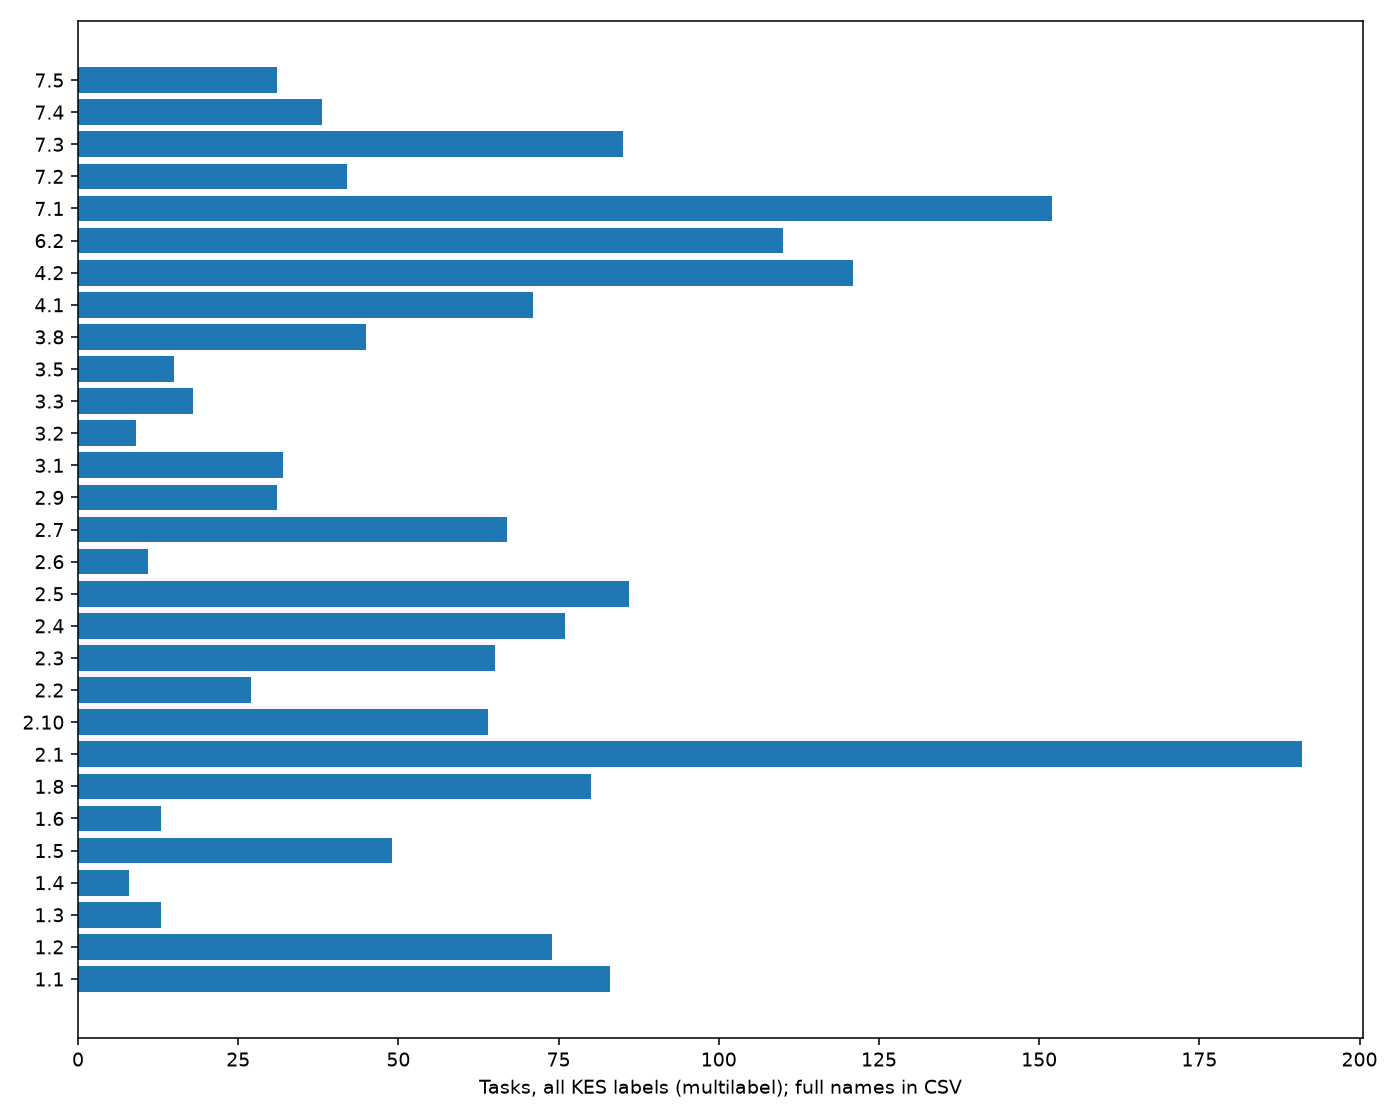

In [16]:
ext_figure('quality','01-label-balance.png')

Проверены файлы изображений, длины, символы, MathML и шаблонные повторы. Нулевой/битый asset не обнаружен; есть один символ замены и 80 задач с zero-width символами. Диагностика HTML-парсера сама по себе не равна повреждению: MathML/HTML требует контекстной проверки. Выброс по длине или числу формул — кандидат на просмотр, а не ошибка и не измеренная трудность для ученика. Порог MAD для изображений вырождается из-за нулевой медианы, поэтому не используется как содержательный классификатор.

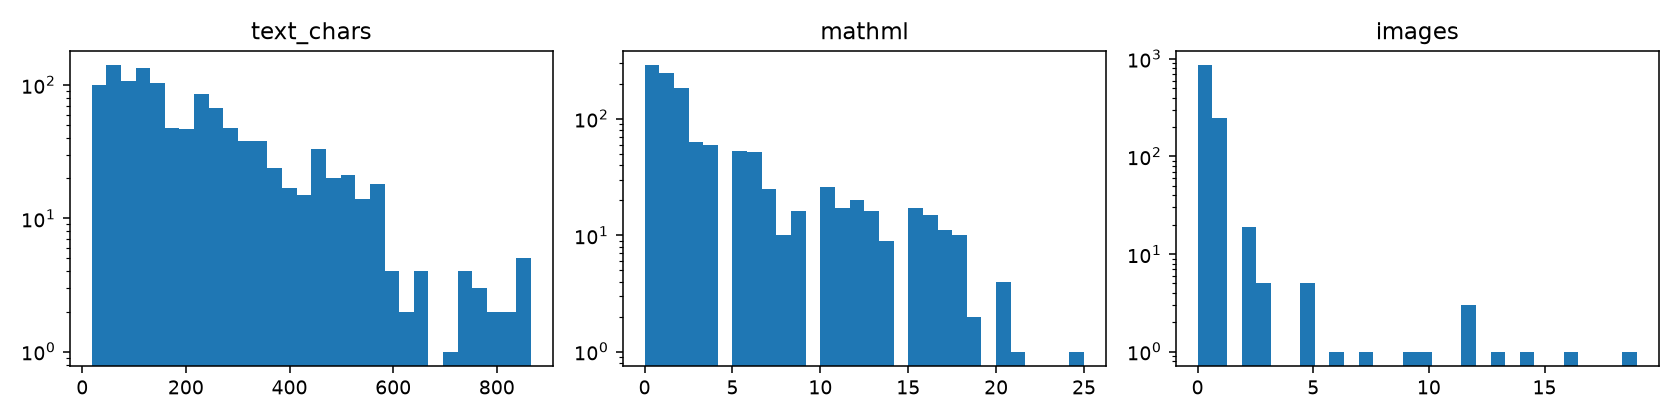

| metric | value | task_id | source_url | candidate_only |
| --- | --- | --- | --- | --- |
| text_chars | 866 | 6e44FB | https://ege.fipi.ru/bank/index.php?proj=AC437B34557F88EA4115D2F374B0A07B&qid=6e44FB | True |
| text_chars | 866 | e8AA65 | https://ege.fipi.ru/bank/index.php?proj=AC437B34557F88EA4115D2F374B0A07B&qid=e8AA65 | True |
| text_chars | 852 | A87FAB | https://ege.fipi.ru/bank/index.php?proj=AC437B34557F88EA4115D2F374B0A07B&qid=A87FAB | True |
| text_chars | 848 | 40BED3 | https://ege.fipi.ru/bank/index.php?proj=AC437B34557F88EA4115D2F374B0A07B&qid=40BED3 | True |
| text_chars | 842 | 6FF25e | https://ege.fipi.ru/bank/index.php?proj=AC437B34557F88EA4115D2F374B0A07B&qid=6FF25e | True |

In [17]:
ext_figure('quality','02-structure.png')
ext_table(ext_rows('quality','outlier-top5.csv')[:5], list(ext_rows('quality','outlier-top5.csv')[0])[:5])

Обычное извлечение текста теряет отношения. Например, в `4CBD4E` дробь $1/7$ становится `1 7`, а степень $(1/7)^{x+4}$ — последовательностью символов без границ основания и показателя. Структурные токены `MFRAC` и `MSUP` сохраняют тип и вложенность узлов. Это техническая сохранность записи, не понимание математики. Ниже — сохранённый конкретный пример и сравнение модальностей.

| task_id | tag | flattened | semantic |
| --- | --- | --- | --- |
| 4CBD4E | mfrac |  1 7  | MFRAC MN 1 END_MN MN 7 END_MN END_MFRAC |

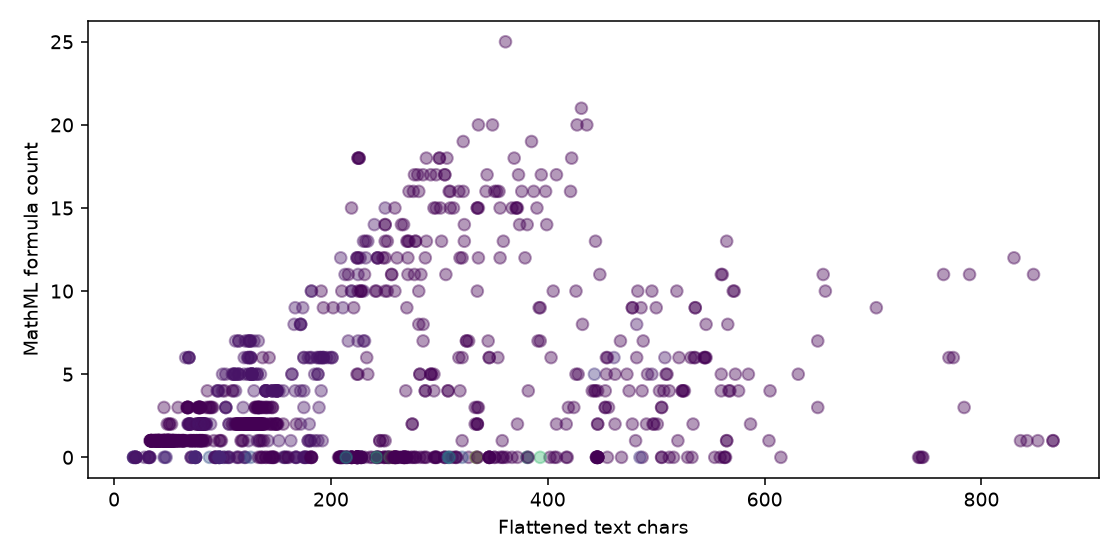

In [18]:
example_flat = ext_json('quality','flatten-examples.json')[1]
ext_table([example_flat], ['task_id','tag','flattened','semantic'])
ext_figure('quality','03-multimodal.png')

### 11.3. Вспомогательный routing baseline

Цель — предсказать первую метку КЭС по условию. Это маршрутизация к разделу банка, а не решение задачи, оценка LLM, диагностика ученика или качество тьютора. Реализованы NumPy majority, multinomial Naive Bayes и TF–IDF cosine 1NN; DL не обучался. Из входа исключены ID, URL, метаданные КЭС, ответы, решения и аудит. Словарь и веса строятся на train; test не подбирает модель.

Group split удерживает числовые шаблоны целиком: train/dev/test = 789/176/183, test — 154 группы. Группировка по всему банку — заранее заданная transductive проверка целостности, не обучение на test-метках. В test есть классы с единичной поддержкой; интервалы bootstrap считаются по группам. Random split имеет 21 test-задачу с шаблоном из train; group — ни одной. На этом seed завышение random-качества **не показано**.

Первичный baseline заранее зафиксирован как semantic NB: accuracy 0.6776, macro-F1 0.4308, top-3 0.8634. Структурное представление не улучшает все модели: NB хуже plain NB (0.7377 / 0.4804), semantic 1NN лучше plain 1NN (0.8251 / 0.6886 против 0.7705 / 0.6307). Random semantic NB имеет ту же accuracy, random semantic 1NN — немного ниже group. Полезен сам анализ зависимости от представления, а не обещание неизбежного роста.

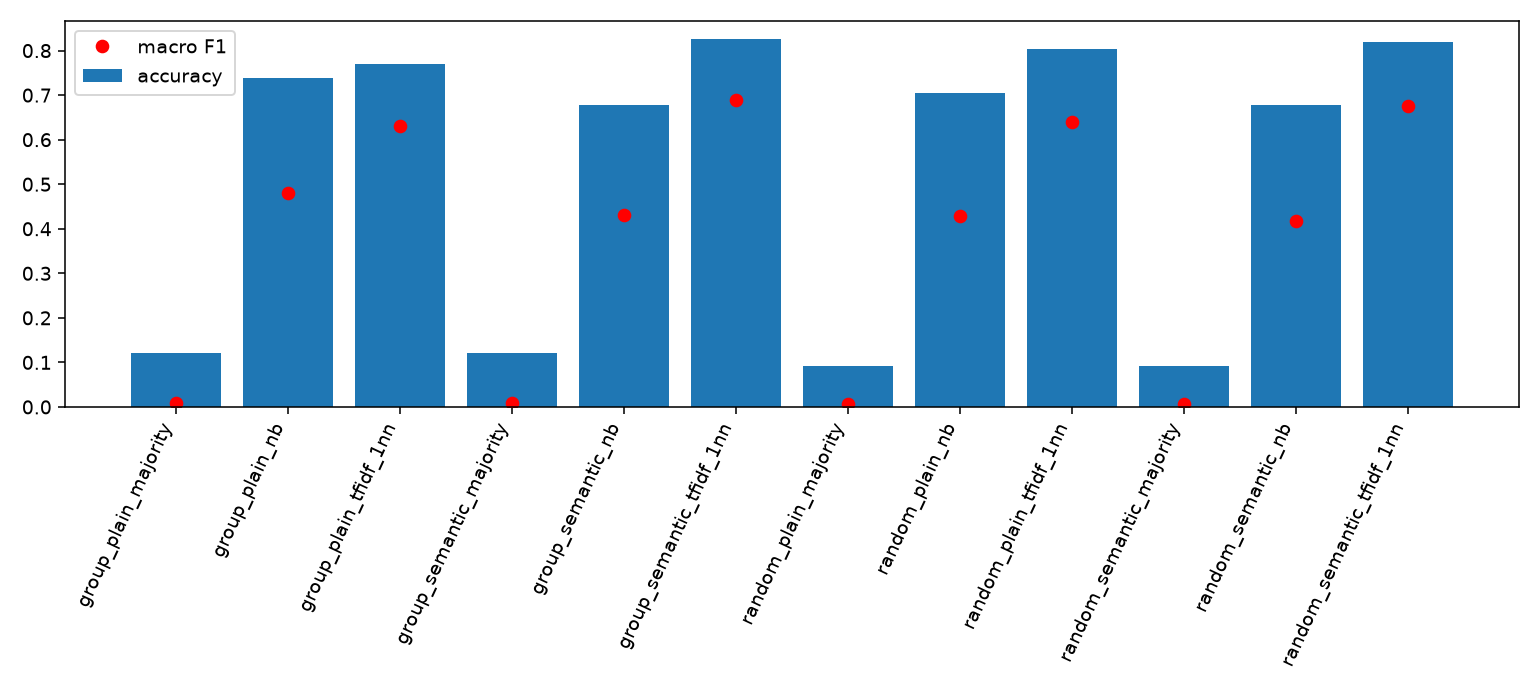

| model | accuracy | macro_f1 | top3_accuracy |
| --- | --- | --- | --- |
| group_semantic_majority | 0.12021857923497267 | 0.00825515947467167 | 0.366120218579235 |
| group_semantic_nb | 0.6775956284153005 | 0.4308219199727511 | 0.8633879781420765 |
| group_semantic_tfidf_1nn | 0.825136612021858 | 0.6886012116129927 | 0.9562841530054644 |
| random_semantic_majority | 0.09289617486338798 | 0.006538461538461539 | 0.34972677595628415 |
| random_semantic_nb | 0.6775956284153005 | 0.4169881711872559 | 0.8797814207650273 |
| random_semantic_tfidf_1nn | 0.819672131147541 | 0.6762997261398797 | 0.9672131147540983 |

| метрика | нижняя | верхняя |
| --- | --- | --- |
| accuracy | 0.597824568860821 | 0.7525831113170393 |
| macro_f1 | 0.35292737332433705 | 0.47871395117123905 |
| top3_accuracy | 0.8011687599681021 | 0.9197914438502673 |

In [19]:
ext_figure('baseline','01-model-comparison.png')
metrics11 = [r for r in extension['baseline']['metrics'] if r['partition']=='test' and 'semantic' in r['model']]
ext_table(metrics11, ['model','accuracy','macro_f1','top3_accuracy'])
ext_table([{'метрика':k,'нижняя':v[0],'верхняя':v[1]} for k,v in extension['baseline']['group_bootstrap_ci95'].items()], ['метрика','нижняя','верхняя'])

NB объясним через вклад токенов в разность log-вероятностей классов. Частые тематические слова помогают, но пунктуация и оформление также несут корреляции. Ниже — характерные признаки и две ошибки с локальными вкладами; ошибкой считается несовпадение с операционной первой КЭС, а не доказанная математическая ошибочность условия.

In [20]:
features11=ext_rows('baseline','distinctive-features.csv')
ext_table([r for r in features11 if r['rank']=='1'][:8], ['class_label','feature','distinctive_log_probability'])
errors11=[r for r in ext_json('baseline','explanations.json') if not r['correct']][:2]
assert len(errors11)==2, 'Two saved baseline error explanations required'
for err in errors11:
    display(Markdown('**'+err['task_id']+'**: первая КЭС '+err['actual']+' → предсказано '+err['predicted']))
    ext_table(err['features'][:4], ['token','count','margin'])

| class_label | feature | distinctive_log_probability |
| --- | --- | --- |
| 1.1 | чисел | 4.015938352881714 |
| 1.2 | - | 4.0853513655826905 |
| 1.3 | mroot | 3.2683220559696 |
| 1.4 | выражения | 2.125468705083926 |
| 1.5 | sin | 3.4115873034423556 |
| 1.6 | log | 2.375303002287958 |
| 2.1 | км | 3.2735515418783123 |
| 2.10 |  /  | 3.5071549363829337 |

**0BD320**: первая КЭС 2.4 → предсказано 2.3

| token | count | margin |
| --- | --- | --- |
| end_mtext | 9 | -5.3020666673559695 |
| mtext | 9 | -5.3020666673559695 |
| mo | 9 | 3.803068781094442 |
| end_mo | 9 | 3.803068781094442 |

**0C4928**: первая КЭС 2.3 → предсказано 2.1

| token | count | margin |
| --- | --- | --- |
| в | 5 | 21.609735918192822 |
| , | 9 | 13.030285936538545 |
| / | 2 | 7.19272945465093 |
| end_mstyle | 9 | 7.076636206478493 |

### 11.4. Проверенная аугментация оформления

Детерминированная смена пробелов, эквивалентных Unicode-символов и HTML-обёрток проверена по сигнатурам математической структуры, чисел/операторов и assets: 1148/1148 проходят. Semantic token invariance — 100%; взвешенные counts после дублирования совпадают точно. Поэтому прироста качества здесь нет: это полезная отрицательная проверка и основание нормализовать оформление. Устойчивость постоянного majority сама по себе не свидетельствует о полезности. Варианты не увеличивают число независимых задач; замена чисел и геометрические трансформации этим опытом не проверены.

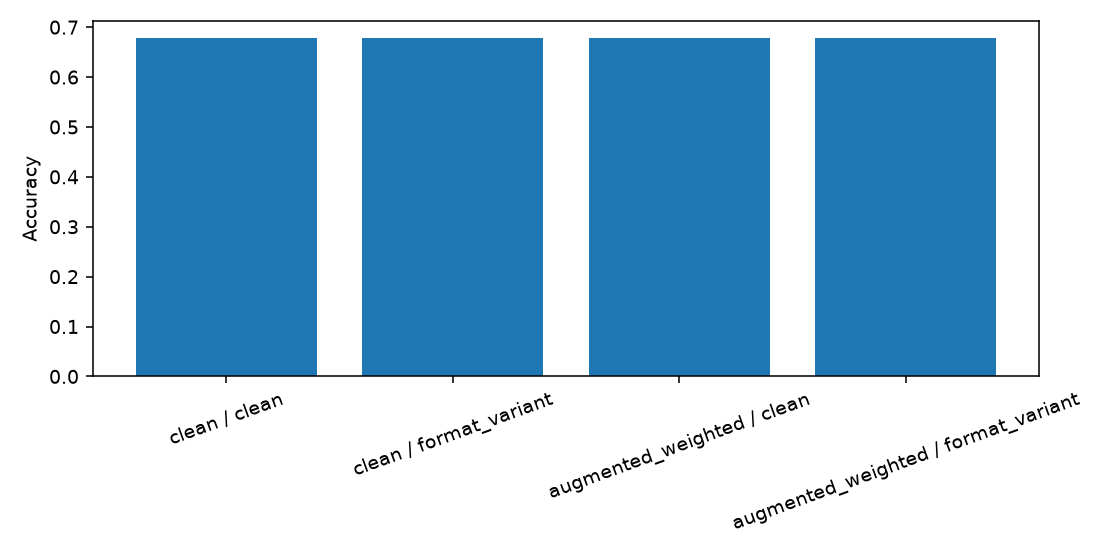

In [21]:
ext_figure('baseline','04-format-robustness.png')

### 11.5. KC и независимые семейства упражнений

Частота задач с KC может завышать запас разнообразной практики. В этом корпусе массовой шаблонной избыточности не обнаружено: 247 задач образуют 239 семейств; для linear_equation — 26 задач и 23 семейства. Числовые варианты одного шаблона всё равно не дают независимых контекстов. Ниже число задач сопоставлено с числом консервативных шаблонных семейств. Это структурная обеспеченность банка, а не доказанный перенос освоения. В mixed247 у 5 из 144 определений нет поддержки, у 50 — одно семейство, у 26 — два и у 63 — не менее трёх; `catalog_nodes` в таблице означает полный размер фиксированного каталога, не число поддержанных определений. В Sol50 44 из 50 задач содержат несопоставленных кандидатов; полностью сопоставлены 59 из 186 шагов. Каталог фиксирован и предварителен, new_candidate между задачами не консолидированы; редакторские назначения отличаются по происхождению от независимых аудитов.

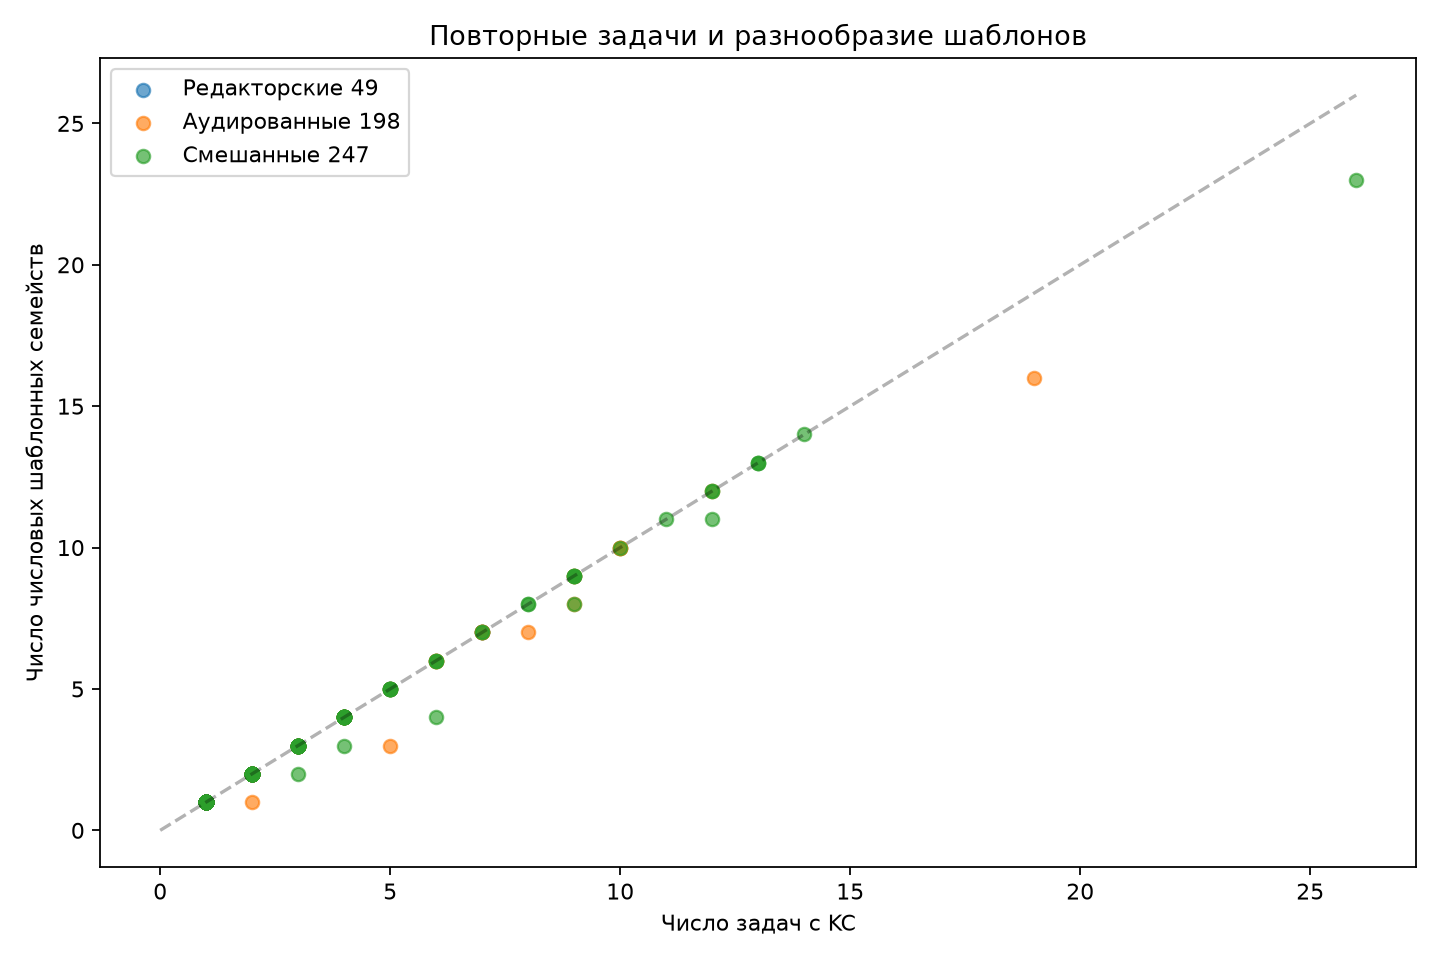

| слой | included_tasks | families | catalog_nodes | tasks_with_unmatched_candidates |
| --- | --- | --- | --- | --- |
| mixed247 | 247 | 239 | 144 | 178 |
| audited198 | 198 | 191 | 144 | 178 |
| historical_editorial50 | 49 | 49 | 144 | 0 |
| historical_independent50 | 49 | 49 | 144 | 45 |
| sol50 | 50 | 48 | 144 | 44 |
| Opus100 | 99 | 98 | 144 | 89 |

In [22]:
ext_figure('families','task-vs-family.png')
family11=extension['families']['populations']
ext_table([{'слой':k,**{x:v.get(x,'') for x in ['included_tasks','families','catalog_nodes','tasks_with_unmatched_candidates']}} for k,v in family11.items()], ['слой','included_tasks','families','catalog_nodes','tasks_with_unmatched_candidates'])

### 11.6. Что выполнено и как применять в тьюторе

| Критерий | Исполненный результат | Граница |
|---|---|---|
| Специфика домена | Текст, MathML, рисунки; конкретная потеря дроби/степени | Структура не равна математическому пониманию |
| Баланс классов | Все КЭС против первой метки; редкие классы сохранены | 26 классов routing не равны навыкам |
| Качество, объём, выбросы | 1148 условий, 250 разборов, технические проверки и кандидаты аномалий | Нет официальных ответов и экспертного эталона |
| Простой ML baseline | Majority, NB, TF–IDF 1NN; random/group; признаки, ошибки, bootstrap | Вспомогательная маршрутизация, не DL и не оценка тьютора |
| Аугментация | Проверены инварианты и предсказания форматного преобразования | Прироста и новых независимых задач нет |
| Предметная модель | KC × задачи × шаблонные семейства | Не prerequisites и не адаптивная рекомендация |

В будущем прототипе результаты задают требования к сохранению формул и рисунков, подсказке раздела для нового условия и отбору упражнений с разными контекстами. Результаты не обновляют профиль ученика: для этого нужны наблюдаемые самостоятельные попытки, различение помощи и решения, проверка математической корректности и учебный эксперимент.

Полные сохранённые отчёты: [250 разборов](../../data/annotation/analyses/2026-11-09-fipi-checkpoint-250-v1/report.md), [доменное качество](../../data/annotation/analyses/2026-11-09-domain-quality-v1/report.md), [routing baseline](../../data/annotation/analyses/2026-11-09-routing-baseline-v1/report.md), [KC и семейства](../../data/annotation/analyses/2026-11-09-kc-families-v1/report.md). Их provenance фиксируют происхождение и хеши; исполнение главы проверяет SHA сохранённых артефактов и независимые счётчики manifest, не вызывает collectors.

## 12. Обновление 10 ноября: опубликованные данные Богдана

Разделы 1–10 сохраняют исходные 100 задач; глава 11 описывает отдельный срез 9 ноября на 250 задачах. Здесь добавлены только **65 уже сохранённых пар** из следующей брони Богдана. Новые решения, аудиты и условия не генерировались. Оставшиеся 35 из этой брони в опубликованном коммите не обработаны.

Источник — отдельная ветка `annotation/bogdan108-fipi-next-100`, коммит `2937b04d5e2df51da67e6a1a2a6c784204960a4e`. Эти материалы ещё не объединены с рабочей веткой. У Богдана есть собственный отчёт с тем же названием «EDA-250», но другим составом задач; обе версии сохранены раздельно.

### Состав и повторный расчёт

Состав устанавливается по уникальным ID и активным попыткам. Единое правило `solved` и отсутствие блокирующего аудита дают 312 задач в частотах из 315 сохранённых. Эта техническая политика не доказывает математическую правильность.

| срез | сохранено | в частотах |
| --- | --- | --- |
| baseline100 | 100 | 98 |
| baseline200 | 200 | 197 |
| saved250 | 250 | 247 |
| published315 | 315 | 312 |
| published315_review_holdout | 315 | 311 |

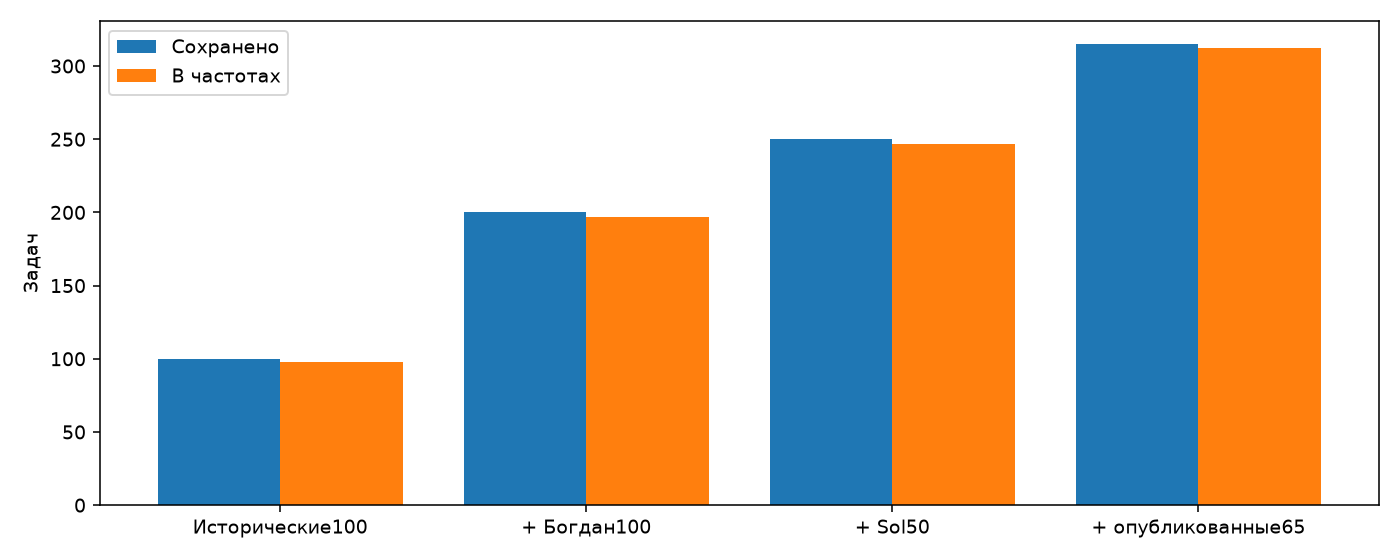

In [23]:
from checkpoint2_saved_refresh import load as load_refresh, REL as REFRESH_DIR
refresh, refresh_hashes = load_refresh(ROOT)
ext_table([{'срез':name,'сохранено':refresh['populations'][name]['selected_n'],'в частотах':refresh['populations'][name]['included_n']} for name in ['baseline100','baseline200','saved250','published315','published315_review_holdout']], ['срез','сохранено','в частотах'])
display(Image(filename=str(ROOT / REFRESH_DIR / 'figures/progression.png')))

### Что именно проверено

Схемы всех новых 65 пар, ссылки шагов и KC, буквальные цитаты, хеши условий, промптов, исполнений и изображений проверены локально повторно. У пяти партий сохранены исходные технические проверки. Метрики прежних 100 и 250 задач пересчитаны и совпали с сохранёнными результатами.

Исходные 35 ячеек исторического ноутбука сохранены: в первой меняется только навигация; остальные тексты и код совпадают с версией Git, а 11 исходных графиков совпадают побитово. Доли статусов ниже относятся к локальным кандидатам KC, а не к точности решений.

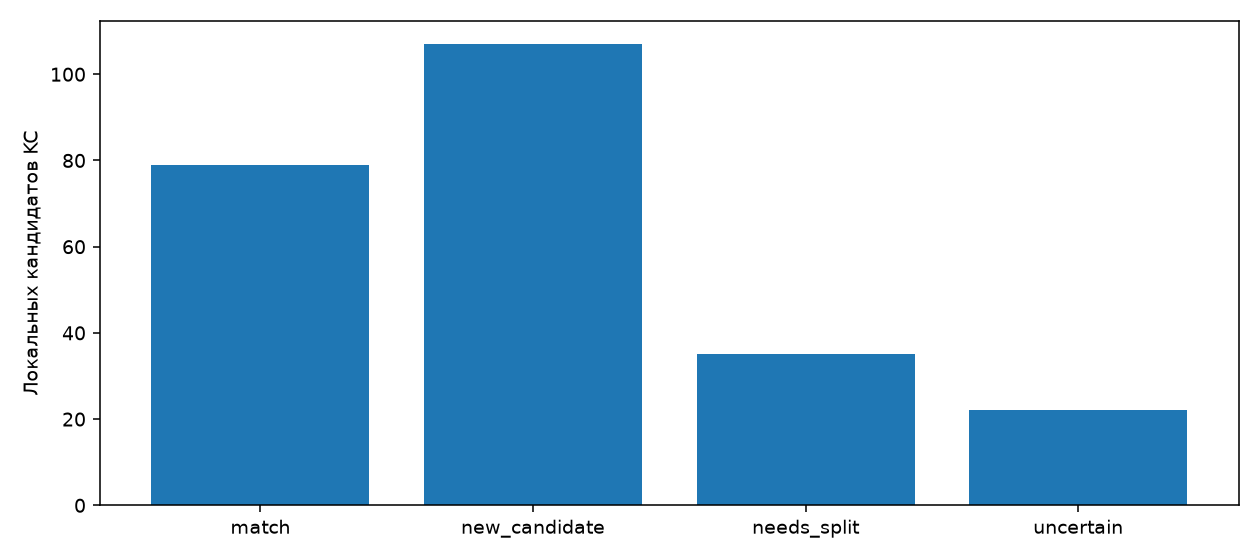

In [24]:
display(Image(filename=str(ROOT / REFRESH_DIR / 'figures/new65-audit.png')))

### Что требует содержательного просмотра

В `0B2322` сам источник отмечает неразрешённое расхождение ответов **2/3** при чтении графика производной. Случай остаётся в исходной политике, но отдельно показан расчёт с его временным исключением: 311 задач в частотах. Это очередь на просмотр, а не исправление авторского ответа или заключение о неверном решении.

В таблице сохранены и остальные математические замечания нового слоя. Их необходимо рассматривать по условиям и решениям. Согласие агентов, полные JSON и успешный пересчёт не заменяют предметной проверки человеком.

In [25]:
ext_table(refresh['math_input_flags'], ['task_id','kind','blocking','description'])

| task_id | kind | blocking | description |
| --- | --- | --- | --- |
| FAAE63 | math | False | Формулировка неточна: ∠ABM=90°−∠BAC следует из прямоугольного треугольника, образованного AB, BM и AC (с прямым углом при основании перпендикуляра из B), а не из треугольника ABC; в ABC равенство 90°−∠BAC=∠ACB. Итог верен, соответствие не подрывается. |
| 0B2322 | math | False | На рисунке отметка x3 визуально совпадает с локальным максимумом (f'=0), а x6 лежит между двумя пиками на нисходящем участке; если x3 — экстремум, положительна производная только в x2 и x5 и ответ 2, а не 3. Классификация x3 и x5 требует сверки с эталоном; на тип KC это не влияет. |
| 724631 | math | False | Формулировка s2 оборвана («при a=1 даёт A≥100·... проверка»); оценка 100a²>100a+99 верна при a≥2, случай a=1 закрыт лишь в warnings: (10+b)(10+c)≥100+10b+10c>100+10b+c требует c≥1 или b≥1 — при b=c=0 произведение 100 < 100+... равно 100=A? Для A=100 B=C=10, 10·10=100 — равенство возможно, но B=10 = 10a+b и одновременно 10b+c=0 недопустимо; вывод s2 формально требует оговорки этого граничного случая. На итоговый ответ не влияет. |

В README опубликованной серии дополнительно зафиксированы перезаписи ответа автора `F7B7A1` и ответа аудитора `720230` перед финальным сохранением. Это отклонения от правила неизменяемых исходных попыток. Локальная проверка подтверждает хеши полученных финальных файлов, но не восстанавливает утраченную историю их правок. Эти ограничения происхождения сохраняются при сравнении слоёв.

### Вывод и применение

Новый слой позволяет обновить описательную статистику существующей разметки, сохранив прежние срезы для сравнения. Его происхождение и неразрешённые замечания остаются видимыми. Перед использованием спорных решений в учебной сессии требуется содержательная проверка; частоты и совместная встречаемость KC не являются подтверждённой программой обучения.

Исходные 100/98 и срез 250 не заменены новыми числами. Датированное дополнение показывает опубликованное состояние корпуса, а не готовность всех задач из бронирования и не качество будущего тьютора.